<a href="https://www.kaggle.com/code/maryammoghaddasbayat/aipolicy-9nov?scriptVersionId=367293008" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Stakeholder Power and Governance Asymmetries in AI Policy: from Recognition to Enforceable Accountability
**Complete, executable Kaggle notebook (Python 3).** Rewritten from the first step to the last in line with the revised research proposal (*Stakeholder Power in AI Policy*, revised 2 November).

### Research questions (from the proposal)
| RQ | Question |
|---|---|
| **RQ1** | How are different stakeholder groups represented across AI governance policies and jurisdictions? |
| **RQ2** | To what extent do AI policies translate stakeholder recognition into clearly defined rights, protections and obligations? |
| **RQ3** | What accountability mechanisms (oversight, enforcement and remedies) are established to support compliance with AI policy obligations? |
| **RQ4** | How do stakeholder protection and enforceable accountability differ across jurisdictions and policy implementation stages? |

### Conceptual framework (proposal, section 4)
**1 Recognition** (who is named?) → **2 Protection** (what right or safeguard is stated?) → **3 Accountability** (who has a duty, and who checks it?) → **4 Implementation** (what measure supports delivery?). The framework does not assume that every instrument contains all four stages; a missing link in the tracker is *not* proof that no protection exists in the real world.

### How this notebook is organised
| Section | Content | RQ |
|---|---|---|
| 0 | Setup, plotting style, helper functions | all |
| 1 | Load the four AIPolicyTracker CSV tables, data dictionary and quality checks | all |
| 2 | Merge, derive variables (law type, format, tier), corpus description | all |
| 3 | Codebook and the two rule-based coders (A and B) | all |
| 4 | Inter-method reliability (Cohen's kappa, bootstrap CI) and the conservative reconciled coding | all |
| 5 | Representation of stakeholder groups | RQ1 |
| 6 | Recognition-to-protection funnel, binding versus non-binding, obligation profile | RQ2 |
| 7 | Accountability features, accountability index, remedy levels, regression models | RQ3 |
| 8 | Actors, jurisdiction indices, concentration, implementation records | RQ4 |
| 9 | Coder-sensitivity analysis | all |
| 10 | Evidence-at-a-glance figure and summary table | all |
| 11 | Zip all results into one folder | all |

### Outputs (rules followed)
* One notebook, executable top to bottom on Kaggle (attach the dataset *AIpolicy_29OK* containing `policies`, `obligations`, `jurisdictions` and `implementation` CSV files; internet is **not** needed).
* Every figure is displayed here **and** saved as a vector **PDF**; every table is displayed here **and** saved as a **CSV**.
* The last cell zips all result files into **one** archive (`aipolicy_results.zip`).
* Fixed random seed (42). Both coders are rule-based programs (no machine-learning or generative-AI classifier).

### Important scope and validation qualifications (revised)
* The coded text is the tracker-derived policy text assembled in the notebook (title, summary, applicability fields and linked obligation descriptions), **not necessarily the complete official legal instrument**. Findings describe what is identifiable in the tracker text. They do not establish that a right or remedy is absent from the full law.
* Coder A and Coder B are two rule-based coding procedures. Their kappa statistics measure **inter-method agreement**, not independent human inter-coder reliability or construct validity.
* A stratified human-validation worksheet is exported as `human_validation_template.csv`. Reviewers must inspect the official policy sources and independently code the selected cases. Do not describe human validation as completed until the worksheet has been completed and analysed.
* The conservative minimum of the two rule-based scores is a provisional working/reproducibility choice, not a substitute for adjudication. If completed, a `human_adjudication.csv` file can override document-level remedy and inclusion codes using the documented columns.
* RQ2 separates **document-level remedies** from **stakeholder-linked protections**. A remedy somewhere in a document must not be reported as a remedy available to a named stakeholder unless the coding explicitly links them.
* Regression models are exploratory associations. Sparse format-by-legal-status cells and a limited number of positive outcomes restrict independent-effect interpretation. No causal claims are made.
* The implementation table is analysed descriptively only; its small number of records and limited linkage do not support an evaluation of implementation effectiveness.


## 0. Setup, plotting style and helper functions
**What this cell does.** Imports the libraries, fixes the random seed and the analysis parameters, defines a colour-blind-safe colour palette, and defines the helpers used everywhere: `show()` (display a table and save it as CSV), `savefig()` (display a figure and save it as PDF), a Wilson confidence interval, and a 2×2 comparison helper that returns counts, percentages, odds ratio (Haldane–Anscombe corrected when a cell is zero) and Fisher's exact test.

**Research questions.** None directly; this cell guarantees that every later result is reproducible and is saved in the required formats (tables → `.csv`, figures → `.pdf`).

**Parameters worth knowing:** `MIN_DOCS` = minimum number of policies for a jurisdiction to appear in jurisdiction-level tables; `MIN_EVENTS` = minimum events and non-events before a regression is estimated; `N_BOOT` = bootstrap resamples for kappa intervals.

In [1]:
import os, re, sys, zipfile, warnings, platform
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.metrics import cohen_kappa_score
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 80)

try:
    from IPython.display import display, Markdown
except ImportError:                      # allows the notebook to run as a plain script
    display = print
    Markdown = str

# ------------------------------------------------------------------ parameters
SEED = 42
N_BOOT = 1000          # bootstrap resamples for kappa confidence intervals
MIN_EVENTS = 10        # minimum events AND non-events before a logit is estimated
MIN_DOCS = 3           # minimum policies per jurisdiction in jurisdiction-level tables
SOURCE_URL = "https://aipolicytracker.org/open-data"
LICENCE = "CC BY 4.0"
ACCESS_DATE = "2026-11-02"
DATA_FOLDER = "AIpolicy_data"
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------ output folder
ON_KAGGLE = os.path.exists("/kaggle/working")
BASE = "/kaggle/working" if ON_KAGGLE else "."
OUT = os.path.join(BASE, "aipolicy_results")
os.makedirs(OUT, exist_ok=True)
SAVED = {"tables": [], "figures": []}

# ------------------------------------------------------------------ colour palette (Okabe-Ito, colour-blind safe)
PAL = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "pink": "#CC79A7",
     "sky": "#56B4E9", "red": "#D55E00", "yellow": "#F0E442", "grey": "#7a7a7a", "ink": "#1b1b1b"}
LAW_COL = {"binding (hard law)": PAL["blue"], "non-binding (soft law)": PAL["orange"]}
REMEDY_COL = [ "#d4d4d4", PAL["sky"], PAL["blue"], PAL["red"] ]        # 0 none, 1 symbolic, 2 procedural, 3 explicit
REMEDY_LAB = ["0 None", "1 Symbolic", "2 Procedural", "3 Explicit right/remedy"]
LEVEL_COL = {"passive": PAL["sky"], "procedural": PAL["blue"], "explicit": PAL["red"]}
GROUP_COL = [PAL["blue"], PAL["orange"], PAL["green"], PAL["pink"], PAL["sky"]]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.bbox": "tight", "pdf.fonttype": 42,
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "legend.frameon": False, "axes.titleweight": "bold"})

# ------------------------------------------------------------------ helpers
def show(obj, title, fname=None, index=True):
    '''Display a table with a bold title and save it as <fname>.csv in the results folder.'''
    display(Markdown(f"**{title}**"))
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    display(obj)
    if fname:
        obj.to_csv(os.path.join(OUT, f"{fname}.csv"), index=index)
        SAVED["tables"].append(f"{fname}.csv")

def savefig(name, title=None):
    '''Add an optional figure title, save the current figure as a vector PDF and display it.'''
    fig = plt.gcf()
    if title:
        fig.suptitle(title, fontsize=12, fontweight="bold", y=1.02)
    fig.savefig(os.path.join(OUT, f"{name}.pdf"), format="pdf")
    SAVED["figures"].append(f"{name}.pdf")
    plt.show()
    plt.close(fig)

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontweight="bold", fontsize=11, ha="right")

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return centre - half, centre + half

def odds_ratio_2x2(a, b, c, d):
    '''Odds ratio of [[a,b],[c,d]] with Haldane-Anscombe 0.5 correction if any cell is zero, plus 95% CI.'''
    if min(a, b, c, d) == 0:
        a, b, c, d = a + .5, b + .5, c + .5, d + .5
    est = (a * d) / (b * c); se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return est, float(np.exp(np.log(est) - 1.96 * se)), float(np.exp(np.log(est) + 1.96 * se))

def compare_binary(df, flag, group_col, g1, g2):
    '''Compare a 0/1 indicator between two groups: counts, %, odds ratio (g1 vs g2) and Fisher exact p.'''
    x1 = df.loc[df[group_col] == g1, flag]; x2 = df.loc[df[group_col] == g2, flag]
    a, b = int(x1.sum()), int(len(x1) - x1.sum()); c, d_ = int(x2.sum()), int(len(x2) - x2.sum())
    _, p = stats.fisher_exact([[a, b], [c, d_]])
    o, lo, hi = odds_ratio_2x2(a, b, c, d_)
    return {"n_g1": len(x1), "events_g1": a, "pct_g1": round(100 * a / max(len(x1), 1), 1),
            "n_g2": len(x2), "events_g2": c, "pct_g2": round(100 * c / max(len(x2), 1), 1),
            "odds_ratio": round(o, 2), "OR_CI_low": round(lo, 2), "OR_CI_high": round(hi, 2), "fisher_p": p}

print("Setup complete | seed", SEED, "| output folder:", os.path.abspath(OUT))

Setup complete | seed 42 | output folder: /kaggle/working/aipolicy_results


## 1. Load the four AIPolicyTracker tables, data dictionary and quality checks
**What this cell does.** Searches `/kaggle/input` for the four CSV files (`policies`, `obligations`, `jurisdictions`, `implementation`), loads them, and keeps an **unchanged read-only copy** of each (`*_raw`) for audit, as required in proposal section 6.2. It then builds (i) a **data dictionary** (file name, rows, columns, source URL, licence, access date) and (ii) a **data-quality table** (duplicate identifiers, share of missing values in the key text fields, unmatched keys).

**Research questions.** All (data foundation). The quality table shows how much text is available for the rule-based coders; thin text is a limitation for every RQ.

**Outputs.** `t01_data_dictionary.csv`, `t02_data_quality.csv`.

In [2]:
def find_csv(name):
    """Locate the CSV whose file name contains `name`; prefer the attached AIpolicy dataset folder."""
    hits = []
    for root in ["/kaggle/input", "."]:
        if not os.path.exists(root):
            continue
        for dirpath, _, files in os.walk(root):
            for fn in files:
                if fn.lower().endswith(".csv") and name.lower() in fn.lower():
                    hits.append(os.path.join(dirpath, fn))
    if not hits:
        raise FileNotFoundError("No CSV containing '" + name + "' found. Attach the Kaggle dataset first.")
    key = re.sub(r"[^a-z0-9]", "", DATA_FOLDER.lower())

    def rank(p):
        norm = re.sub(r"[^a-z0-9]", "", p.lower())
        return (0 if key in norm else 1, len(p))

    return sorted(hits, key=rank)[0]


NAMES = ["policies", "obligations", "jurisdictions", "implementation"]
PATHS = {n: find_csv(n) for n in NAMES}
pol, obl, jur, imp = (pd.read_csv(PATHS[n]) for n in NAMES)
pol_raw, obl_raw, jur_raw, imp_raw = pol.copy(), obl.copy(), jur.copy(), imp.copy()   # unchanged audit copies
print({k: os.path.basename(v) for k, v in PATHS.items()})

dictionary = pd.DataFrame({
    "file": [os.path.basename(PATHS[n]) for n in PATHS],
    "rows": [len(f) for f in (pol, obl, jur, imp)],
    "columns": [f.shape[1] for f in (pol, obl, jur, imp)],
    "role_in_analysis": ["Unit of coding and regression (policy documents)",
                         "Obligation categories and actor references (RQ2, RQ4)",
                         "Jurisdiction type / tier (RQ1, RQ4)",
                         "Implementation records (RQ4)"],
    "source_url": SOURCE_URL, "licence": LICENCE, "accessed_on": ACCESS_DATE
}, index=list(PATHS))
show(dictionary, "Table 1. Data dictionary of the four AIPolicyTracker files", "t01_data_dictionary")

def pct_missing(frame, col):
    return round(100 * frame[col].isna().mean(), 1) if col in frame.columns else np.nan

quality = pd.DataFrame([
    ["policies", "duplicate slug", int(pol["slug"].duplicated().sum())],
    ["policies", "% missing summary_plain", pct_missing(pol, "summary_plain")],
    ["policies", "% missing who_it_applies_to", pct_missing(pol, "who_it_applies_to")],
    ["policies", "% missing instrument_type", pct_missing(pol, "instrument_type")],
    ["obligations", "duplicate slug", int(obl["slug"].duplicated().sum())],
    ["obligations", "% missing summary", pct_missing(obl, "summary")],
    ["obligations", "% missing practical_action", pct_missing(obl, "practical_action")],
    ["obligations", "obligations whose policy is not in policies", int((~obl["policy"].isin(pol["slug"])).sum())],
    ["jurisdictions", "duplicate slug", int(jur["slug"].duplicated().sum())],
    ["policies", "policies whose jurisdiction is not in jurisdictions", int((~pol["jurisdiction"].isin(jur["slug"])).sum())],
    ["implementation", "rows", len(imp)],
], columns=["table", "check", "value"])
show(quality, "Table 2. Data-quality checks (duplicates, missing text, unmatched keys)", "t02_data_quality", index=False)

{'policies': 'aipolicytracker-policies.csv', 'obligations': 'aipolicytracker-obligations.csv', 'jurisdictions': 'aipolicytracker-jurisdictions.csv', 'implementation': 'aipolicytracker-implementation.csv'}


**Table 1. Data dictionary of the four AIPolicyTracker files**

,file,rows,columns,role_in_analysis,source_url,licence,accessed_on
policies,aipolicytracker-policies.csv,244,25,Unit of coding and regression (policy documents),https://aipolicytracker.org/open-data,CC BY 4.0,2026-11-02
obligations,aipolicytracker-obligations.csv,117,18,"Obligation categories and actor references (RQ2, RQ4)",https://aipolicytracker.org/open-data,CC BY 4.0,2026-11-02
jurisdictions,aipolicytracker-jurisdictions.csv,249,20,"Jurisdiction type / tier (RQ1, RQ4)",https://aipolicytracker.org/open-data,CC BY 4.0,2026-11-02
implementation,aipolicytracker-implementation.csv,8,27,Implementation records (RQ4),https://aipolicytracker.org/open-data,CC BY 4.0,2026-11-02


**Table 2. Data-quality checks (duplicates, missing text, unmatched keys)**

,table,check,value
0,policies,duplicate slug,0.0
1,policies,% missing summary_plain,0.0
2,policies,% missing who_it_applies_to,67.6
3,policies,% missing instrument_type,0.0
4,obligations,duplicate slug,0.0
5,obligations,% missing summary,0.0
6,obligations,% missing practical_action,0.0
7,obligations,obligations whose policy is not in policies,0.0
8,jurisdictions,duplicate slug,0.0
9,policies,policies whose jurisdiction is not in jurisdictions,0.0


## 2. Merge the tables, derive the analysis variables and describe the corpus
**What this cell does.** Merges jurisdiction metadata into the policies (checking that every policy matches exactly one jurisdiction) and derives the variables used throughout:
* **`law_type`** – binding (hard law) versus non-binding (soft law), from the tracker's `is_binding` flag;
* **`format`** – statute (act, regulation, bill, executive order), strategy, policy, soft guidance (guidance, framework, standard, code of practice) or consultation; **`format3`** collapses strategy, policy and consultation to avoid sparse cells in regressions (proposal 6.2);
* **`tier`** – country, state (state, region, territory) or supranational;
* **coding text** – title + plain summary + applicability statement + the text of all linked obligations (this is what the two coders read).

It then reports the corpus composition and draws **Figure 1** (three panels: legal status, format, tier), plus a cross-tabulation of format by legal status so readers can see how strongly "binding" and "statute" overlap.

**Research questions.** Describes the sample on which RQ1–RQ4 are answered. **Outputs.** `t03_corpus_composition.csv`, `t04_format_by_law_type.csv`, `fig01_corpus_composition.pdf`.

Policies matched to a jurisdiction record: 1.0


**Table 3. Corpus composition (N policy documents)**

,variable,category,n_policies,share_pct
0,law_type,non-binding (soft law),163,66.8
1,law_type,binding (hard law),81,33.2
2,format,strategy,99,40.6
3,format,statute,76,31.1
4,format,soft_guidance,35,14.3
5,format,policy,30,12.3
6,format,consultation,4,1.6
7,tier,country,164,67.2
8,tier,state,67,27.5
9,tier,supranational,13,5.3


**Table 4. Document format by legal status (counts)**

law_type,binding (hard law),non-binding (soft law),All
format,,,
consultation,0,4,4
policy,6,24,30
soft_guidance,4,31,35
statute,71,5,76
strategy,0,99,99
All,81,163,244


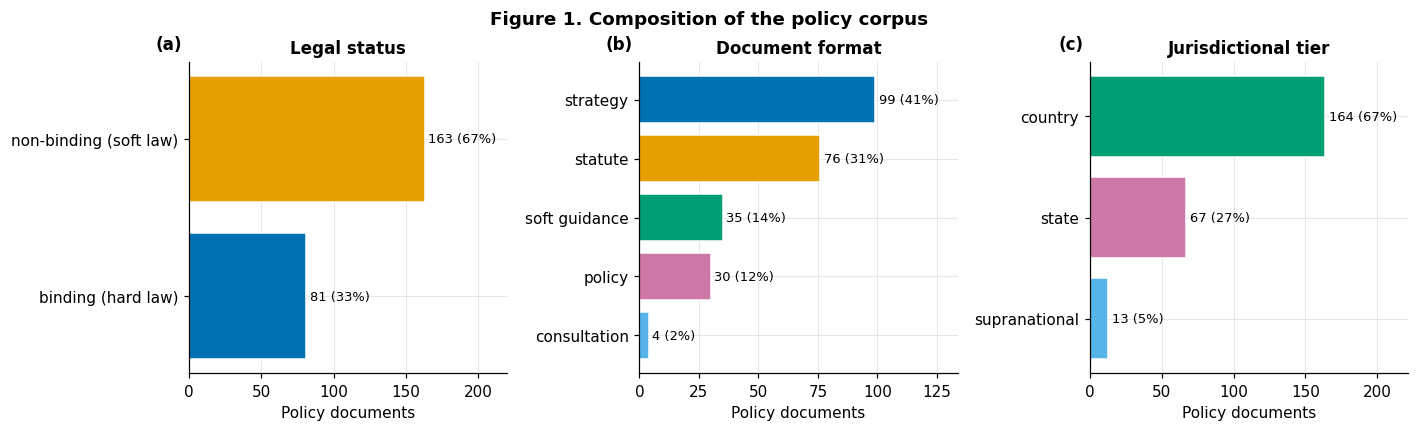

Policy records: 244 | obligations: 117 | jurisdictions: 249 | implementation: 8


In [3]:
for col in ["adopted_on", "published_on", "in_force_on", "applies_from"]:
    if col in pol.columns:
        pol[col] = pd.to_datetime(pol[col], errors="coerce")
if "published_on" in imp.columns:
    imp["published_on"] = pd.to_datetime(imp["published_on"], errors="coerce")

jt = jur[["slug", "jurisdiction_type", "region", "subregion"]].rename(columns={"slug": "jurisdiction"})
pol = pol.merge(jt, on="jurisdiction", how="left", validate="many_to_one")
print("Policies matched to a jurisdiction record:", round(pol["jurisdiction_type"].notna().mean(), 3))

FORMAT_MAP = {"act": "statute", "regulation": "statute", "bill": "statute", "executive_order": "statute",
              "strategy": "strategy", "policy": "policy", "guidance": "soft_guidance", "framework": "soft_guidance",
              "standard": "soft_guidance", "code_of_practice": "soft_guidance", "consultation": "consultation"}
pol["format"] = pol["instrument_type"].map(FORMAT_MAP).fillna("other")
pol["format3"] = pol["format"].replace({"strategy": "strategy_policy", "policy": "strategy_policy",
                                        "consultation": "strategy_policy"})
pol["tier"] = pol["jurisdiction_type"].replace({"territory": "state", "region": "state"})
pol["is_binding"] = pol["is_binding"].fillna(False).astype(bool)
pol["binding"] = pol["is_binding"].astype(int)
pol["law_type"] = np.where(pol["is_binding"], "binding (hard law)", "non-binding (soft law)")

for col in ["title", "summary", "practical_action"]:
    if col not in obl.columns:
        obl[col] = ""
obl["obl_text"] = (obl["title"].fillna("").astype(str) + ". " + obl["summary"].fillna("").astype(str) + ". "
                   + obl["practical_action"].fillna("").astype(str))
obl["is_binding"] = obl["is_binding"].fillna(False).astype(bool)

obl_agg = (obl.groupby("policy", dropna=False)
              .agg(n_obligations=("slug", "count"), obl_text=("obl_text", lambda x: " ".join(x.dropna().astype(str))))
              .reset_index().rename(columns={"policy": "slug"}))
pol = pol.merge(obl_agg, on="slug", how="left", validate="one_to_one")
pol["n_obligations"] = pol["n_obligations"].fillna(0).astype(int)

for col in ["title", "summary_plain", "who_it_applies_to"]:
    if col not in pol.columns:
        pol[col] = ""
pol["text"] = (pol["title"].fillna("").astype(str) + ". " + pol["summary_plain"].fillna("").astype(str) + ". "
               + pol["who_it_applies_to"].fillna("").astype(str) + ". " + pol["obl_text"].fillna("").astype(str))

# ---- Table 3: corpus composition
parts = []
for col in ["law_type", "format", "tier"]:
    tmp = pol[col].value_counts(dropna=False).rename("n_policies").to_frame()
    tmp["variable"] = col; tmp["category"] = tmp.index.astype(str)
    parts.append(tmp.reset_index(drop=True))
desc = pd.concat(parts, ignore_index=True)
desc["share_pct"] = (100 * desc["n_policies"] / len(pol)).round(1)
show(desc[["variable", "category", "n_policies", "share_pct"]], "Table 3. Corpus composition (N policy documents)",
     "t03_corpus_composition", index=False)

fmt_by_law = pd.crosstab(pol["format"], pol["law_type"], margins=True)
show(fmt_by_law, "Table 4. Document format by legal status (counts)", "t04_format_by_law_type")

# ---- Figure 1: corpus composition
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
specs = [("law_type", "Legal status", [LAW_COL.get(k, PAL["grey"]) for k in pol["law_type"].value_counts().index]),
         ("format", "Document format", [PAL["blue"], PAL["orange"], PAL["green"], PAL["pink"], PAL["sky"], PAL["red"]]),
         ("tier", "Jurisdictional tier", [PAL["green"], PAL["pink"], PAL["sky"], PAL["orange"]])]
for ax, (col, ttl, cols) in zip(axes, specs):
    vc = pol[col].fillna("missing").value_counts()
    bars = ax.barh([str(i).replace("_", " ") for i in vc.index][::-1], vc.values[::-1],
                   color=(cols * 3)[:len(vc)][::-1], edgecolor="white")
    for b, v in zip(bars, vc.values[::-1]):
        ax.text(v + vc.max() * 0.015, b.get_y() + b.get_height() / 2, f"{v} ({100 * v / len(pol):.0f}%)", va="center", fontsize=8.5)
    ax.set_xlim(0, vc.max() * 1.35); ax.set_title(ttl); ax.set_xlabel("Policy documents")
for ax, l in zip(axes, "abc"):
    panel(ax, l)
plt.tight_layout()
savefig("fig01_corpus_composition", "Figure 1. Composition of the policy corpus")
print("Policy records:", len(pol), "| obligations:", len(obl), "| jurisdictions:", len(jur), "| implementation:", len(imp))

## 3. Codebook and the two rule-based coders (A and B)
**What this cell does.** Defines the **codebook** (proposal 6.3) and implements two independent **rule-based coders**. Both are keyword/regular-expression programs, not machine-learning or generative-AI classifiers.

* **Coder A** (conservative): whole-word patterns and a tiered remedy lexicon.
* **Coder B** (broader): stem-based patterns plus modal-verb logic: aspirational wording such as *should*, *encouraged*, *voluntary* or *aims to* caps the remedy at the symbolic level unless a procedural mechanism is stated.

Each policy text is split into sentences. A **stakeholder group** (consumers/individuals, workers, children, vulnerable groups, civil society) receives a score **in the same sentence** as a safeguard or right: **0** not mentioned, **1** passive recognition, **2** procedural protection (notice, explanation, complaint, appeal, human review, opt-out), **3** explicit individual right or remedy (compensation, damages, redress, legal claim). *Public enforcement* (fines, sanctions, prosecution) is kept as a **separate** indicator and is not counted as an individual remedy. Four further **document-level features** follow the proposal's codebook: *duty-holder* (an actor in the same sentence as an obligation word), *oversight and enforcement* (audit, supervision, monitoring, competent authority, sanction), *complaint and remedy* (document remedy ≥ 2) and *implementation support* (standard, guideline, code, template or procedure).

**Research questions.** Creates the measures for all four RQs: recognition (RQ1), protection levels (RQ1–RQ2), accountability features (RQ3), actors (RQ4). The same actor lexicon `ACTORS` is reused in section 8.

**Outputs.** `t05_codebook.csv`.

In [4]:
GROUPS = ["consumers_individuals", "workers", "children", "vulnerable_groups", "civil_society"]
GROUP_LABEL = {"consumers_individuals": "Consumers / individuals", "workers": "Workers", "children": "Children",
               "vulnerable_groups": "Vulnerable groups", "civil_society": "Civil society"}

STAKEHOLDERS_A = {
    "consumers_individuals": r"\b(consumers?|individuals?|data subjects?|natural persons?|citizens?|end[- ]users?|residents?|members of the public|people)\b",
    "workers": r"\b(workers?|employees?|job applicants?|candidates?|labou?r|staff)\b",
    "children": r"\b(children|child|minors?|youth|young people)\b",
    "vulnerable_groups": r"\b(vulnerable (persons?|people|groups?)|persons? with disabilities|people with disabilities|older persons?|elderly people|patients?|marginali[sz]ed groups?)\b",
    "civil_society": r"\b(civil society|public interest groups?|non[- ]governmental organi[sz]ations?|NGOs?|affected communities|community representatives|public consultation)\b"}
STAKEHOLDERS_B = {
    "consumers_individuals": r"(consumer|individual|data subject|natural person|citizen|end[- ]user|resident|member of the public)",
    "workers": r"(worker|employee|job applicant|candidate|labou?r|staff)",
    "children": r"(child|minor|juvenile|young person|youth)",
    "vulnerable_groups": r"(vulnerable (person|people|group)|disabilit|older person|elderly|patient|marginali[sz]ed group)",
    "civil_society": r"(civil societ|public interest group|non[- ]governmental|\bNGO\b|affected communit|community representative|public consultation)"}

PROCEDURAL_A = (r"\b(appeal\w*|contest\w*|challenge\w*|complain\w*|complaint\w*|grievance\w*|human review|human intervention|"
                r"notice|notification|explanation|right to access|right to object|right to erasure|right to opt[- ]out|"
                r"opt[- ]out|request for review|review procedure)\b")
PROCEDURAL_B = (r"(appeal|contest|challeng|complain|grievance|human review|human intervention|notice|notif|explanation|"
                r"access right|right to object|erasure right|opt-?out|request.*review|review procedure)")
RIGHT_REMEDY_A = (r"\b(right to (compensation|damages|redress|a remedy)|right of action|private right of action|"
                  r"claim for compensation|seek compensation|obtain compensation|obtain redress|entitled to compensation|"
                  r"entitled to damages|judicial remedy|legal remedy|remedy for (the )?individual)\b")
RIGHT_REMEDY_B = (r"(right to (compensation|damages|redress|a remedy)|right of action|private right of action|"
                  r"claim.*compensation|seek.*compensation|obtain.*(compensation|redress)|entitled to (compensation|damages)|"
                  r"judicial remedy|legal remedy|remedy.*individual)")
PUBLIC_ENFORCEMENT_A = r"\b(fines?|financial penalties|administrative penalties|sanctions?|administrative measures|prosecution|prosecuted)\b"
PUBLIC_ENFORCEMENT_B = r"(fine|financial penalt|administrative penalt|sanction|administrative measure|prosecut)"
SYMBOLIC_A = (r"\b(principles?|encourag\w+|promot\w+|voluntar\w+|should|aspirational|ethical|ethics|trustworthy|"
              r"responsible AI|guidance|best practice)\b")
SYMBOLIC_B = r"(principle|encourag|promot|voluntar|should|aspirational|ethic|trustworthy|responsible AI|guidance|best practice|recommend)"
SOFT_MODAL = re.compile(r"\b(should|encouraged|recommended|voluntary|aims? to|seeks? to)\b", re.I)

# Actor lexicon (also used for the RQ4 actor analysis in section 8).
ACTORS = {
    "provider_developer": r"\b(providers?|developers?|manufacturers?|vendors?|suppliers?)\b",
    "deployer_user_organisation": r"\b(deployers?|operators?|organisations?|organizations?|businesses|companies|employers?|controllers?|processors?)\b",
    "importer_distributor": r"\b(importers?|distributors?|authori[sz]ed representatives?)\b",
    "public_authority": r"\b(public (authorit|bod|sector)\w*|government|agenc(y|ies)|regulators?|ministr\w+|authorit(y|ies))\b",
    # This category identifies model providers/developers only when the text names
    # a general-purpose/foundation-model actor. "Systemic risk" and "high-impact"
    # describe risks or system classifications, not actors, so they are excluded.
    "gpai_frontier": r"\b(general[- ]purpose (?:AI )?models?|foundation models?|frontier models?)\b"}

# Document-level features from the codebook.
DUTY_ACTOR_A = "|".join(f"(?:{p})" for p in ACTORS.values())
DUTY_ACTOR_B = r"(provider|deployer|developer|operator|manufacturer|importer|distributor|controller|processor|competent authorit|regulator|supplier|vendor)"
DUTY_WORD_A = r"\b(must|shall|required|requires?|obliged|obligat\w+|responsible|dut(y|ies)|ensure|ensuring|comply|compliance)\b"
DUTY_WORD_B = r"(must|shall|requir|oblig|responsib|dut(y|ies)|ensur|compl)"
OVERSIGHT_A = (r"\b(audit\w*|supervis\w+|monitor\w+|oversight|inspect\w+|competent authorit\w+|market surveillance|"
               r"conformity assessment|compliance (check|review|process)|enforcement authorit\w+|regulators?)\b")
OVERSIGHT_B = r"(audit|supervis|monitor|oversight|inspect|competent authorit|market surveillance|conformity assess|compliance|enforc|regulator)"
IMPL_A = (r"\b(standards?|guidelines?|codes? of (practice|conduct)|templates?|procedures?|implementing (acts?|measures?)|"
          r"technical specifications?)\b")
IMPL_B = r"(standard|guideline|code of (practice|conduct)|template|procedure|implementing (act|measure)|technical specification)"

def split_sentences(text):
    '''Split on sentence-ending punctuation; fragments of <= 3 characters are dropped.'''
    return [p.strip() for p in re.split(r"(?<=[.!?])\s+", str(text)) if len(p.strip()) > 3]

def remedy_tier(sentence, method):
    '''0 none; 1 symbolic; 2 procedural; 3 explicit individual right/remedy.'''
    right, proc, sym = ((RIGHT_REMEDY_A, PROCEDURAL_A, SYMBOLIC_A) if method == "A"
                        else (RIGHT_REMEDY_B, PROCEDURAL_B, SYMBOLIC_B))
    if re.search(right, sentence, re.I): return 3
    if re.search(proc, sentence, re.I): return 2
    if re.search(sym, sentence, re.I): return 1
    return 0

def code_policy(text, method):
    '''Return group scores (0-3), document remedy (0-3), and the 0/1 indicators for public enforcement,
    duty-holder, oversight and implementation support for one policy text.'''
    lex = STAKEHOLDERS_A if method == "A" else STAKEHOLDERS_B
    actor_re, duty_re, pe_re, over_re, impl_re = (
        (DUTY_ACTOR_A, DUTY_WORD_A, PUBLIC_ENFORCEMENT_A, OVERSIGHT_A, IMPL_A) if method == "A"
        else (DUTY_ACTOR_B, DUTY_WORD_B, PUBLIC_ENFORCEMENT_B, OVERSIGHT_B, IMPL_B))
    scores = {g: 0 for g in GROUPS}
    remedy = public_enf = duty = 0
    for s in split_sentences(text):
        tier = remedy_tier(s, method)
        if method == "B" and SOFT_MODAL.search(s) and tier < 2:      # modal cap on aspirational wording
            tier = min(tier, 1)
        remedy = max(remedy, tier)
        if re.search(pe_re, s, re.I): public_enf = 1
        if re.search(actor_re, s, re.I) and re.search(duty_re, s, re.I): duty = 1
        for g, pat in lex.items():
            if re.search(pat, s, re.I):                               # group + safeguard/right in the SAME sentence
                scores[g] = max(scores[g], tier)
    oversight = int(bool(re.search(over_re, str(text), re.I)))
    impl = int(bool(re.search(impl_re, str(text), re.I)))
    return scores, remedy, public_enf, duty, oversight, impl

def apply_coder(method):
    res = [code_policy(t, method) for t in pol["text"]]
    out = pd.DataFrame([r[0] for r in res]).add_prefix(f"{method}_grp_")
    out[f"{method}_remedy"] = [r[1] for r in res]
    out[f"{method}_public_enforcement"] = [r[2] for r in res]
    out[f"{method}_duty_holder"] = [r[3] for r in res]
    out[f"{method}_oversight"] = [r[4] for r in res]
    out[f"{method}_impl_support"] = [r[5] for r in res]
    return out

pol = pd.concat([pol.reset_index(drop=True), apply_coder("A"), apply_coder("B")], axis=1)

def derive(prefix):
    '''Derive recognition, protection and accountability indicators from the coder columns with the given prefix
    ("A_", "B_", or "" for the reconciled coding).'''
    g = [f"{prefix}grp_{x}" for x in GROUPS]
    pol[f"{prefix}n_groups"] = (pol[g] > 0).sum(axis=1)
    pol[f"{prefix}inclusion"] = (pol[f"{prefix}n_groups"] > 0).astype(int)
    pol[f"{prefix}n_groups_active"] = (pol[g] >= 2).sum(axis=1)
    pol[f"{prefix}enforceable_remedy"] = (pol[f"{prefix}remedy"] == 3).astype(int)
    pol[f"{prefix}procedural_protection"] = (pol[f"{prefix}remedy"] == 2).astype(int)
    pol[f"{prefix}procedural_or_enforceable"] = (pol[f"{prefix}remedy"] >= 2).astype(int)
    pol[f"{prefix}f_right_protection"] = (pol[g] >= 2).any(axis=1).astype(int)
    pol[f"{prefix}f_duty_holder"] = pol[f"{prefix}duty_holder"].astype(int)
    pol[f"{prefix}f_oversight_enforcement"] = ((pol[f"{prefix}oversight"] == 1) | (pol[f"{prefix}public_enforcement"] == 1)).astype(int)
    pol[f"{prefix}f_complaint_remedy"] = (pol[f"{prefix}remedy"] >= 2).astype(int)
    pol[f"{prefix}f_implementation_support"] = pol[f"{prefix}impl_support"].astype(int)
    feats = [f"{prefix}f_{n}" for n in FEATURES]
    pol[f"{prefix}accountability_index"] = pol[feats].sum(axis=1)

FEATURES = ["right_protection", "duty_holder", "oversight_enforcement", "complaint_remedy", "implementation_support"]
FEATURE_LABEL = {"right_protection": "Right / protection", "duty_holder": "Duty-holder",
                 "oversight_enforcement": "Oversight & enforcement", "complaint_remedy": "Complaint & remedy",
                 "implementation_support": "Implementation support"}
derive("A_"); derive("B_")

codebook = pd.DataFrame([
    ["Stakeholder group", "0-3 per group", "Consumers/individuals, workers, children, vulnerable groups, civil society; 0 absent, 1 passive, 2 procedural safeguard, 3 explicit right/remedy (same sentence)."],
    ["Recognition (inclusion)", "0/1", "At least one of the five groups has a score > 0."],
    ["Right or protection", "0/1", "At least one group is linked to a procedural safeguard or explicit right (score >= 2)."],
    ["Duty-holder", "0/1", "A provider, deployer, authority or similar actor appears in the same sentence as an obligation word (must, shall, required, responsible ...)."],
    ["Oversight and enforcement", "0/1", "Monitoring, audit, supervision, competent authority, conformity assessment, regulator, or a sanction/fine/prosecution."],
    ["Complaint and remedy", "0/1", "Document-level remedy score >= 2 (procedural safeguard or explicit right/remedy)."],
    ["Implementation support", "0/1", "A standard, guideline, code, template or procedure is mentioned as supporting delivery."],
    ["Document remedy strength", "0-3", "Highest tier in any sentence: 0 none, 1 symbolic/aspirational, 2 procedural, 3 explicit individual right/remedy."],
    ["Public-enforcement reference", "0/1", "Fines, penalties, sanctions or prosecution (kept separate from individual remedies)."],
    ["Accountability index", "0-5", "Sum of the five features above (right/protection, duty-holder, oversight and enforcement, complaint and remedy, implementation support)."],
], columns=["code", "scale", "operational_meaning"])
show(codebook, "Table 5. Codebook used by both coders", "t05_codebook", index=False)
print("Coding finished for", len(pol), "policy documents (coders A and B).")

**Table 5. Codebook used by both coders**

,code,scale,operational_meaning
0,Stakeholder group,0-3 per group,"Consumers/individuals, workers, children, vulnerable groups, civil society; ..."
1,Recognition (inclusion),0/1,At least one of the five groups has a score > 0.
2,Right or protection,0/1,At least one group is linked to a procedural safeguard or explicit right (sc...
3,Duty-holder,0/1,"A provider, deployer, authority or similar actor appears in the same sentenc..."
4,Oversight and enforcement,0/1,"Monitoring, audit, supervision, competent authority, conformity assessment, ..."
5,Complaint and remedy,0/1,Document-level remedy score >= 2 (procedural safeguard or explicit right/rem...
6,Implementation support,0/1,"A standard, guideline, code, template or procedure is mentioned as supportin..."
7,Document remedy strength,0-3,"Highest tier in any sentence: 0 none, 1 symbolic/aspirational, 2 procedural,..."
8,Public-enforcement reference,0/1,"Fines, penalties, sanctions or prosecution (kept separate from individual re..."
9,Accountability index,0-5,"Sum of the five features above (right/protection, duty-holder, oversight and..."


Coding finished for 244 policy documents (coders A and B).


## 4. Inter-method reliability and the conservative reconciled coding
**What this cell does.** Measures how much the two coders agree: **Cohen's kappa** (quadratic-weighted for 0–3 scores and the accountability index, unweighted for 0/1 indicators) with **bootstrap 95% confidence intervals** and **raw agreement** (kappa is unstable when one category is rare). Kappa is labelled with the Landis–Koch benchmark. **Figure 2** shows kappa with its interval (panel a) and raw agreement (panel b), coloured by variable family.

It then (i) writes an **audit list** of the policies on which the coders disagree, so that disagreements can be checked manually against the linked official source (proposal 6.4), and (ii) builds the **conservative reconciled coding** (the *lower* of A and B for every score), which is the coding used for all substantive results. This is an analytical rule, not a human-validated ground truth.

**Research questions.** All RQs: reliability of the measures. When kappa is undefined (a group that neither coder detects) the raw agreement is reported instead.

**Outputs.** `t06_inter_method_agreement.csv`, `t07_disagreement_audit_list.csv`, `fig02_inter_method_agreement.pdf`.

**Table 6. Inter-method agreement between coder A and coder B (kappa, 95% bootstrap CI, raw agreement)**

,variable,family,kappa,ci_low,ci_high,raw_agreement,landis_koch
0,Group level: Consumers / individuals,Group-level protection score,0.720,0.480,0.882,0.955,substantial
1,Group level: Workers,Group-level protection score,0.917,0.690,1.000,0.996,almost perfect
2,Group level: Children,Group-level protection score,1.000,1.000,1.000,1.000,almost perfect
3,Group level: Vulnerable groups,Group-level protection score,NaN,NaN,NaN,1.000,undefined (no variation)
4,Group level: Civil society,Group-level protection score,1.000,1.000,1.000,1.000,almost perfect
5,Stakeholder inclusion (any),Document-level indicator,0.828,0.705,0.934,0.967,almost perfect
6,Document remedy strength (0-3),Document-level indicator,0.920,0.852,0.977,0.967,almost perfect
7,Explicit enforceable remedy,Document-level indicator,1.000,1.000,1.000,1.000,almost perfect
8,Procedural or enforceable mechanism,Document-level indicator,0.924,0.839,0.982,0.984,almost perfect
9,Public-enforcement reference,Document-level indicator,0.512,0.194,0.772,0.963,moderate


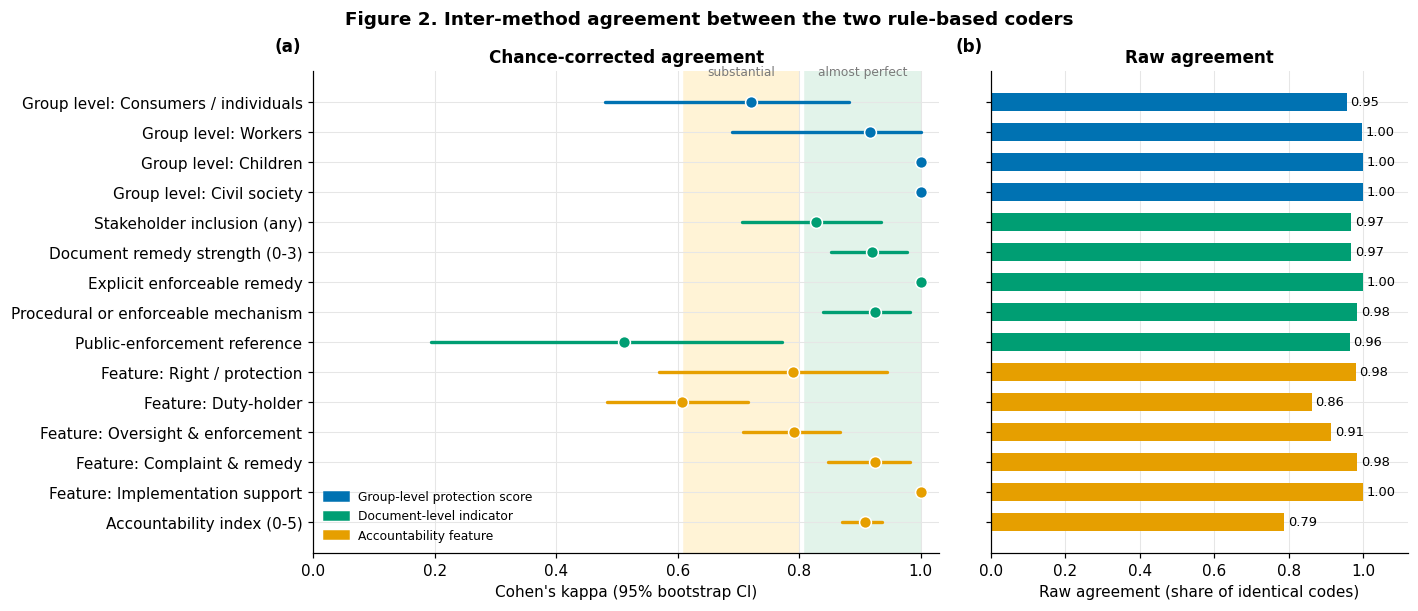

**Table 7. Full audit register of disagreements (27 policies)**

,slug,title,jurisdiction,law_type,A_remedy,B_remedy,A_inclusion,B_inclusion,A_public_enforcement,B_public_enforcement
8,australia-voluntary-ai-safety-standard,Voluntary AI Safety Standard (Australia),australia,non-binding (soft law),2,2,1,0,0,1
10,azerbaijan-ai-strategy-2025-2028,Artificial Intelligence Strategy of the Republic of Azerbaijan for 2025–2028...,azerbaijan,non-binding (soft law),1,1,0,1,0,0
11,bahrain-general-policy-for-the-use-of-artificial-intelligence,General Policy for the Use of Artificial Intelligence,bahrain,non-binding (soft law),1,1,0,0,0,1
21,ca-quebec-law-25-automated-decision-provisions,"Quebec Law 25 (S.Q. 2021, c. 25): provisions on decisions based exclusively ...",ca-quebec,binding (hard law),0,2,0,0,0,0
29,china-measures-for-labeling-artificial-intelligence-generated-and-synthetic-...,Measures for Labeling Artificial Intelligence-Generated and Synthetic Content,china,binding (hard law),0,2,0,0,0,0
45,el-salvador-ai-promotion-law-2025,Ley para el Fomento de la Inteligencia Artificial y Tecnologías Emergentes (...,el-salvador,binding (hard law),1,1,0,0,0,1
50,finland-age-of-artificial-intelligence-2017,Finland's Age of Artificial Intelligence: Turning Finland into a leading cou...,finland,non-binding (soft law),0,1,0,0,0,0
51,france-cnil-ai-how-to-sheets,CNIL recommendations on the development of AI systems and the GDPR (AI how-t...,france,non-binding (soft law),1,1,1,0,0,0
57,greece-law-4961-2022-emerging-technologies,"Νόμος 4961/2022: Αναδυόμενες τεχνολογίες πληροφορικής και επικοινωνιών, ενίσ...",greece,binding (hard law),1,1,1,1,0,0
63,india-ai-governance-guidelines,"India AI Governance Guidelines (MeitY, 2025)",india,non-binding (soft law),1,1,1,0,0,0


Human-validation template exported. Complete it using official policy documents; blank fields are intentional.
No human_adjudication.csv found: conservative minimum-of-two-coders remains the provisional coding.
Working coding | inclusion: 22 | stakeholder-linked procedural/explicit protection: 10 | document-level explicit remedy: 1


In [5]:
def bootstrap_kappa(a, b, weights=None, n_boot=N_BOOT, seed=SEED):
    a, b = np.asarray(a), np.asarray(b)
    r = np.random.default_rng(seed); est = []
    for _ in range(n_boot):
        idx = r.integers(0, len(a), len(a))
        try:
            v = cohen_kappa_score(a[idx], b[idx], weights=weights)
            if np.isfinite(v): est.append(v)
        except Exception:
            continue
    return (np.nan, np.nan) if len(est) < 30 else tuple(np.percentile(est, [2.5, 97.5]))

def landis_koch(k):
    if pd.isna(k): return "undefined (no variation)"
    return ("poor" if k < 0 else "slight" if k <= .20 else "fair" if k <= .40 else "moderate" if k <= .60
            else "substantial" if k <= .80 else "almost perfect")

specs = [(f"Group level: {GROUP_LABEL[g]}", f"A_grp_{g}", f"B_grp_{g}", "quadratic", "Group-level protection score") for g in GROUPS]
specs += [("Stakeholder inclusion (any)", "A_inclusion", "B_inclusion", None, "Document-level indicator"),
          ("Document remedy strength (0-3)", "A_remedy", "B_remedy", "quadratic", "Document-level indicator"),
          ("Explicit enforceable remedy", "A_enforceable_remedy", "B_enforceable_remedy", None, "Document-level indicator"),
          ("Procedural or enforceable mechanism", "A_procedural_or_enforceable", "B_procedural_or_enforceable", None, "Document-level indicator"),
          ("Public-enforcement reference", "A_public_enforcement", "B_public_enforcement", None, "Document-level indicator")]
specs += [(f"Feature: {FEATURE_LABEL[f]}", f"A_f_{f}", f"B_f_{f}", None, "Accountability feature") for f in FEATURES]
specs += [("Accountability index (0-5)", "A_accountability_index", "B_accountability_index", "quadratic", "Accountability feature")]

rows = []
for i, (label, ca, cb, w, family) in enumerate(specs):
    a, b = pol[ca], pol[cb]
    k = cohen_kappa_score(a, b, weights=w) if (a.nunique() > 1 or b.nunique() > 1) else np.nan
    lo, hi = bootstrap_kappa(a, b, weights=w, seed=SEED + i) if pd.notna(k) else (np.nan, np.nan)
    rows.append([label, family, k, lo, hi, (a == b).mean(), landis_koch(k)])
agreement = pd.DataFrame(rows, columns=["variable", "family", "kappa", "ci_low", "ci_high", "raw_agreement", "landis_koch"]).round(3)
show(agreement, "Table 6. Inter-method agreement between coder A and coder B (kappa, 95% bootstrap CI, raw agreement)",
     "t06_inter_method_agreement", index=False)

fam_col = {"Group-level protection score": PAL["blue"], "Document-level indicator": PAL["green"], "Accountability feature": PAL["orange"]}
valid = agreement.dropna(subset=["kappa"]).reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.5, 1]}, sharey=True)
y = np.arange(len(valid))[::-1]
ax1.axvspan(0.61, 0.80, color="#fff3d6", zorder=0); ax1.axvspan(0.81, 1.0, color="#e2f3ea", zorder=0)
for yi, r in zip(y, valid.itertuples()):
    c = fam_col[r.family]
    if pd.notna(r.ci_low):
        ax1.plot([r.ci_low, r.ci_high], [yi, yi], color=c, lw=2.2, solid_capstyle="round")
    ax1.scatter(r.kappa, yi, s=60, color=c, zorder=3, edgecolor="white")
ax1.set_yticks(y); ax1.set_yticklabels(valid["variable"]); ax1.set_xlim(0, 1.03)
ax1.set_xlabel("Cohen's kappa (95% bootstrap CI)"); ax1.set_title("Chance-corrected agreement")
ax1.text(0.705, y.max() + 0.9, "substantial", ha="center", fontsize=8, color=PAL["grey"])
ax1.text(0.905, y.max() + 0.9, "almost perfect", ha="center", fontsize=8, color=PAL["grey"])
ax2.barh(y, valid["raw_agreement"], color=[fam_col[f] for f in valid["family"]], height=0.6)
for yi, v in zip(y, valid["raw_agreement"]): ax2.text(v + 0.01, yi, f"{v:.2f}", va="center", fontsize=8.5)
ax2.set_xlim(0, 1.12); ax2.set_xlabel("Raw agreement (share of identical codes)"); ax2.set_title("Raw agreement")
ax1.legend(handles=[Patch(color=v, label=k) for k, v in fam_col.items()], loc="lower left", fontsize=8)
panel(ax1, "a"); panel(ax2, "b"); plt.tight_layout()
savefig("fig02_inter_method_agreement", "Figure 2. Inter-method agreement between the two rule-based coders")

# ---- Primary reconciliation and transparent human-validation workflow
# Rule-based agreement is INTER-METHOD agreement, not independent human validation.
# Until human adjudication is completed, retain the conservative minimum as a
# pre-specified sensitivity/working coding, and label it accordingly.
for g in GROUPS:
    pol[f"grp_{g}"] = np.minimum(pol[f"A_grp_{g}"], pol[f"B_grp_{g}"])
for v in ["remedy", "public_enforcement", "duty_holder", "oversight", "impl_support"]:
    pol[v] = np.minimum(pol[f"A_{v}"], pol[f"B_{v}"])

# Recalculate all derived measures from the reconciled working codes.
derive("")

# Export a full, auditable disagreement register (not only the first 15 cases).
disagreement_mask = (
    (pol["A_remedy"] != pol["B_remedy"]) |
    (pol["A_inclusion"] != pol["B_inclusion"]) |
    (pol["A_public_enforcement"] != pol["B_public_enforcement"]) |
    np.column_stack([pol[f"A_grp_{g}"].ne(pol[f"B_grp_{g}"]) for g in GROUPS]).any(axis=1)
)
audit_cols = ["slug", "title", "jurisdiction", "law_type",
              "A_remedy", "B_remedy", "A_inclusion", "B_inclusion",
              "A_public_enforcement", "B_public_enforcement"]
audit = pol.loc[disagreement_mask, [c for c in audit_cols if c in pol.columns]].copy()
show(audit, f"Table 7. Full audit register of disagreements ({len(audit)} policies)",
     "t07_disagreement_audit_list", index=False)

# Stratified human-validation sample: one sample from each remedy category where possible,
# plus a reproducible random sample. Human reviewers must inspect the OFFICIAL source text.
VALIDATION_N = min(60, len(pol))
validation_frame = pol.copy()
validation_frame["_stratum"] = validation_frame["remedy"].astype(str)
per_stratum = max(1, VALIDATION_N // max(validation_frame["_stratum"].nunique(), 1))
sample_parts = []
for _, grp in validation_frame.groupby("_stratum", dropna=False):
    sample_parts.append(grp.sample(n=min(len(grp), per_stratum), random_state=SEED))
validation_sample = pd.concat(sample_parts).drop_duplicates("slug")
if len(validation_sample) < VALIDATION_N:
    remaining = validation_frame.loc[~validation_frame["slug"].isin(validation_sample["slug"])]
    validation_sample = pd.concat([
        validation_sample,
        remaining.sample(n=min(VALIDATION_N-len(validation_sample), len(remaining)), random_state=SEED)
    ])
validation_cols = [c for c in ["slug", "title", "jurisdiction", "source_url", "url",
                               "A_remedy", "B_remedy", "remedy", "A_inclusion", "B_inclusion",
                               "inclusion"] if c in validation_sample.columns]
human_validation = validation_sample[validation_cols].copy()
human_validation["official_source_checked"] = ""
human_validation["human_reviewer_1_remedy_0_3"] = ""
human_validation["human_reviewer_2_remedy_0_3"] = ""
human_validation["human_adjudicated_remedy_0_3"] = ""
human_validation["human_reviewer_1_any_stakeholder_0_1"] = ""
human_validation["human_reviewer_2_any_stakeholder_0_1"] = ""
human_validation["human_adjudicated_any_stakeholder_0_1"] = ""
human_validation["notes_and_evidence_quote"] = ""
human_validation.to_csv(os.path.join(OUT, "human_validation_template.csv"), index=False)
SAVED["tables"].append("human_validation_template.csv")
print("Human-validation template exported. Complete it using official policy documents; blank fields are intentional.")

# Optional adjudication file: after human review, save a CSV named
# human_adjudication.csv in the working directory or OUT folder. It must contain
# slug, adjudicated_remedy (0-3), adjudicated_inclusion (0/1).
adjudication_candidates = [
    os.path.join(BASE, "human_adjudication.csv"),
    os.path.join(OUT, "human_adjudication.csv")
]
adjudication_path = next((p for p in adjudication_candidates if os.path.exists(p)), None)
if adjudication_path:
    adjud = pd.read_csv(adjudication_path)
    required = {"slug", "adjudicated_remedy", "adjudicated_inclusion"}
    if not required.issubset(adjud.columns):
        raise ValueError(f"Human adjudication file must contain: {sorted(required)}")
    if adjud["slug"].duplicated().any():
        raise ValueError("Human adjudication file contains duplicate policy slugs.")
    pol = pol.merge(adjud[list(required)], on="slug", how="left", validate="one_to_one")
    # Apply human-adjudicated document-level remedy/inclusion where supplied.
    m = pol["adjudicated_remedy"].notna()
    pol.loc[m, "remedy"] = pol.loc[m, "adjudicated_remedy"].astype(int)
    m_inc = pol["adjudicated_inclusion"].notna()
    pol.loc[m_inc, "inclusion"] = pol.loc[m_inc, "adjudicated_inclusion"].astype(int)
    # Rebuild all document-level variables affected by adjudication.
    pol["enforceable_remedy"] = (pol["remedy"] == 3).astype(int)
    pol["procedural_protection"] = (pol["remedy"] == 2).astype(int)
    pol["procedural_or_enforceable"] = (pol["remedy"] >= 2).astype(int)
    pol["f_complaint_remedy"] = pol["procedural_or_enforceable"]
    pol["accountability_index"] = pol[[f"f_{x}" for x in FEATURES]].sum(axis=1)
    print(f"Applied human adjudication to {int(m.sum())} remedy and {int(m_inc.sum())} inclusion records.")
else:
    print("No human_adjudication.csv found: conservative minimum-of-two-coders remains the provisional coding.")

# If the validation worksheet has been completed and saved as
# human_validation_completed.csv, calculate human-human agreement. This is the
# appropriate place to report human inter-rater reliability; do not report it
# until two independent reviewers have completed the codes.
completed_candidates = [os.path.join(BASE, "human_validation_completed.csv"),
                       os.path.join(OUT, "human_validation_completed.csv")]
completed_path = next((p for p in completed_candidates if os.path.exists(p)), None)
if completed_path:
    hv = pd.read_csv(completed_path)
    r1, r2 = "human_reviewer_1_remedy_0_3", "human_reviewer_2_remedy_0_3"
    if {r1, r2}.issubset(hv.columns):
        hv2 = hv[[r1, r2]].apply(pd.to_numeric, errors="coerce").dropna()
        if len(hv2):
            hk = cohen_kappa_score(hv2[r1], hv2[r2], weights="quadratic")
            print(f"Human-human weighted kappa for remedy score: {hk:.3f} (n={len(hv2)} double-coded cases); report only with reviewer protocol and CI.")
    else:
        print("Completed validation file found, but reviewer remedy columns are missing; human kappa not calculated.")

print("Working coding | inclusion:", int(pol["inclusion"].sum()),
      "| stakeholder-linked procedural/explicit protection:", int(pol["f_right_protection"].sum()),
      "| document-level explicit remedy:", int(pol["enforceable_remedy"].sum()))


## 5. RQ1: How are different stakeholder groups represented across AI governance policies and jurisdictions?
**What this cell does.** Measures the **breadth** and **depth** of stakeholder representation (proposal metrics for RQ1) using the reconciled coding:
* **Breadth:** share of policy documents recognising each group (with Wilson 95% CI) and the mean number of groups per document.
* **Depth:** *passive* recognition (group only named) versus *active* recognition (linked to a procedural safeguard or explicit right) and the **active-to-passive ratio**.
* **Where:** recognition by legal status (Fisher exact test and odds ratio), by document format, by jurisdictional tier, and by jurisdiction (jurisdictions with at least `MIN_DOCS` policies).

**Figures.** *Figure 3* (a) share of documents recognising each group, (b) passive versus procedural versus explicit recognition, (c) binding versus non-binding documents (dumbbell plot). *Figure 4* heat map of recognition by group and jurisdiction. *Figure 5* recognition rate by format and legal status and by tier, with Wilson intervals.

**How to read it.** Low shares mean that most documents do not name the group at all; a low active-to-passive ratio means recognition is mostly passive. Jurisdiction-level percentages rest on few documents and are descriptive only.

**Outputs.** `t08_rq1_recognition_by_group.csv`, `t09_rq1_binding_vs_nonbinding_by_group.csv`, `t10_rq1_inclusion_by_format_tier_law.csv`, `t11_rq1_group_by_jurisdiction.csv`, `fig03`–`fig05`.

**Table 8. RQ1 - Recognition and protection depth by stakeholder group (reconciled coding)**

,n_recognised,pct_of_policies,ci_low,ci_high,passive,procedural,explicit_right_remedy,active_(>=2),active_to_passive_ratio,pct_active_of_recognised
stakeholder_group,,,,,,,,,,
Consumers / individuals,11,4.5,2.5,7.9,5,6,0,6,1.20,54.5
Workers,11,4.5,2.5,7.9,7,4,0,4,0.57,36.4
Children,2,0.8,0.2,2.9,1,1,0,1,1.00,50.0
Vulnerable groups,0,0.0,0.0,1.6,0,0,0,0,NaN,NaN
Civil society,1,0.4,0.1,2.3,1,0,0,0,0.00,0.0


**Breadth of representation**

,0
policies_with_any_group_%,9.000
mean_groups_per_policy,0.102
mean_groups_per_recognising_policy,1.140
policies_with_>=2_groups,3.000


**Table 9. RQ1 - Recognition in binding versus non-binding documents (odds ratio binding vs non-binding; Fisher exact)**

,n_binding,recognising_binding,pct_binding,n_nonbinding,recognising_nonbinding,pct_nonbinding,odds_ratio,OR_CI_low,OR_CI_high,fisher_p
stakeholder_group,,,,,,,,,,
Consumers / individuals,81,6,7.4,163,5,3.1,2.53,0.75,8.55,0.186640
Workers,81,9,11.1,163,2,1.2,10.06,2.12,47.75,0.001034
Children,81,2,2.5,163,0,0.0,10.28,0.49,216.74,0.109290
Vulnerable groups,81,0,0.0,163,0,0.0,2.01,0.04,102.02,1.000000
Civil society,81,0,0.0,163,1,0.6,0.66,0.03,16.50,1.000000
Any group,81,14,17.3,163,8,4.9,4.05,1.62,10.11,0.003305


**Table 10. RQ1 - Recognition by legal status, format and tier (Fisher/chi-square p per variable; sparse cells: descriptive)**

,variable,category,n_policies,n_recognising,pct,ci_low,ci_high,mean_groups,overall_test_p
0,law_type,binding (hard law),81,14,17.3,10.6,26.9,0.210,0.003305
1,law_type,non-binding (soft law),163,8,4.9,2.5,9.4,0.049,0.003305
2,format,consultation,4,0,0.0,0.0,49.0,0.000,0.000239
3,format,policy,30,2,6.7,1.8,21.3,0.067,0.000239
4,format,soft_guidance,35,7,20.0,10.0,35.9,0.200,0.000239
5,format,statute,76,13,17.1,10.3,27.1,0.211,0.000239
6,format,strategy,99,0,0.0,0.0,3.7,0.000,0.000239
7,tier,country,164,11,6.7,3.8,11.6,0.079,0.191895
8,tier,state,67,9,13.4,7.2,23.6,0.134,0.191895
9,tier,supranational,13,2,15.4,4.3,42.2,0.231,0.191895


**Table 11. RQ1 - % of each jurisdiction's policies recognising each group (jurisdictions with >= 3 policies, top 15)**

,n_policies,Consumers / individuals,Workers,Children,Vulnerable groups,Civil society
us-california,7,0.0,14.3,0.0,0.0,0.0
singapore,7,14.3,14.3,0.0,0.0,0.0
international,6,0.0,16.7,0.0,0.0,0.0
us,5,20.0,0.0,0.0,0.0,0.0
uk,4,50.0,0.0,0.0,0.0,0.0
uae,4,0.0,0.0,0.0,0.0,0.0
us-illinois,4,0.0,25.0,0.0,0.0,0.0
india,4,25.0,0.0,0.0,0.0,0.0
australia,3,0.0,0.0,0.0,0.0,0.0
canada,3,0.0,0.0,0.0,0.0,0.0


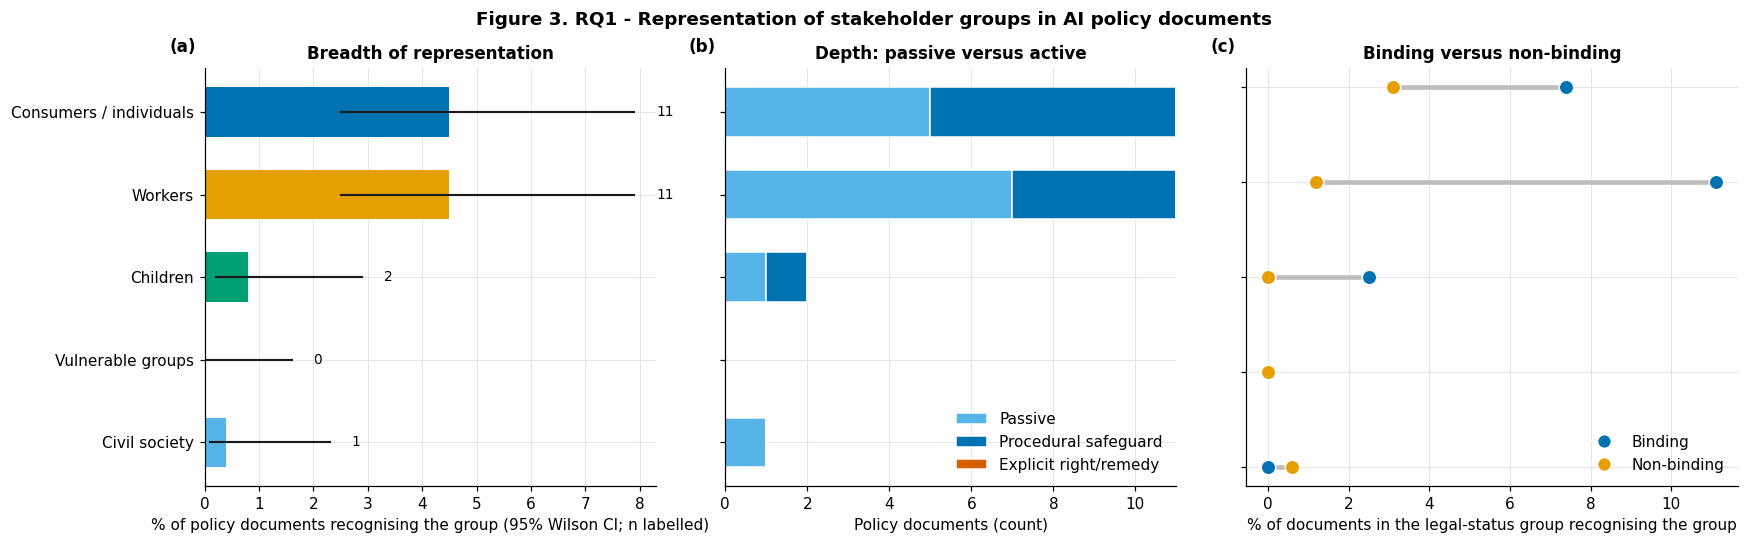

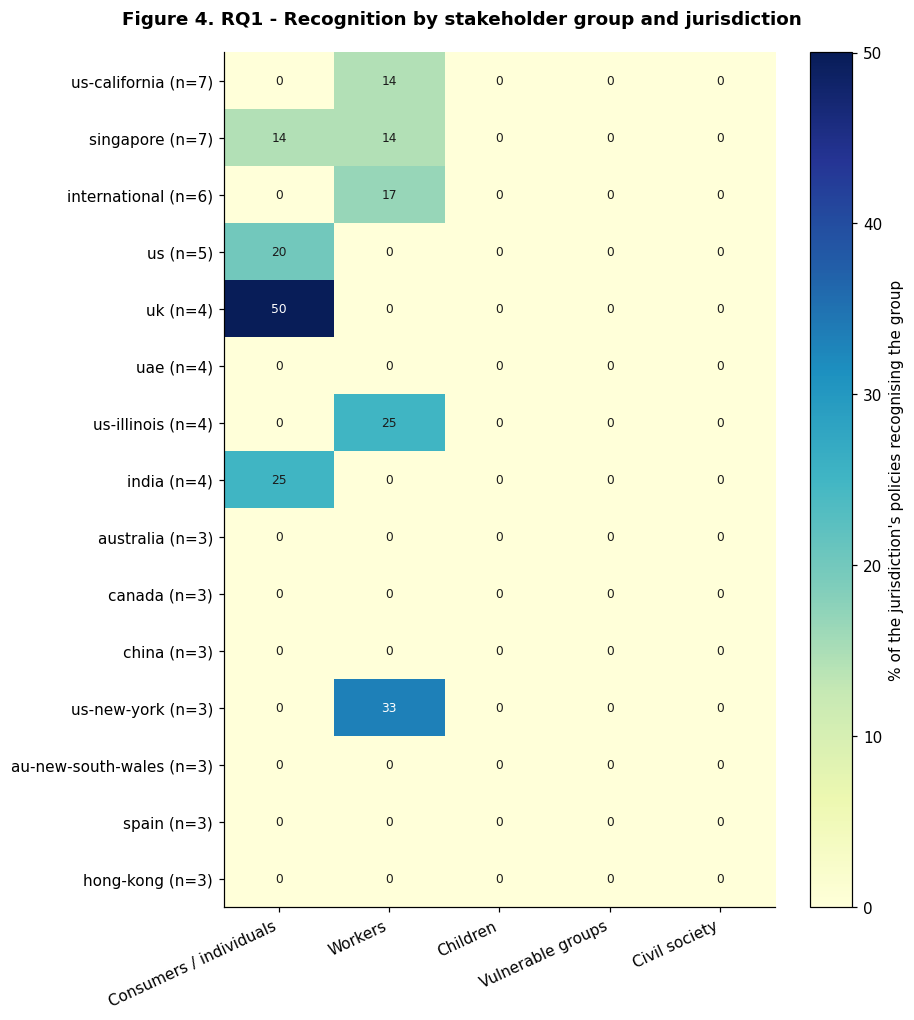

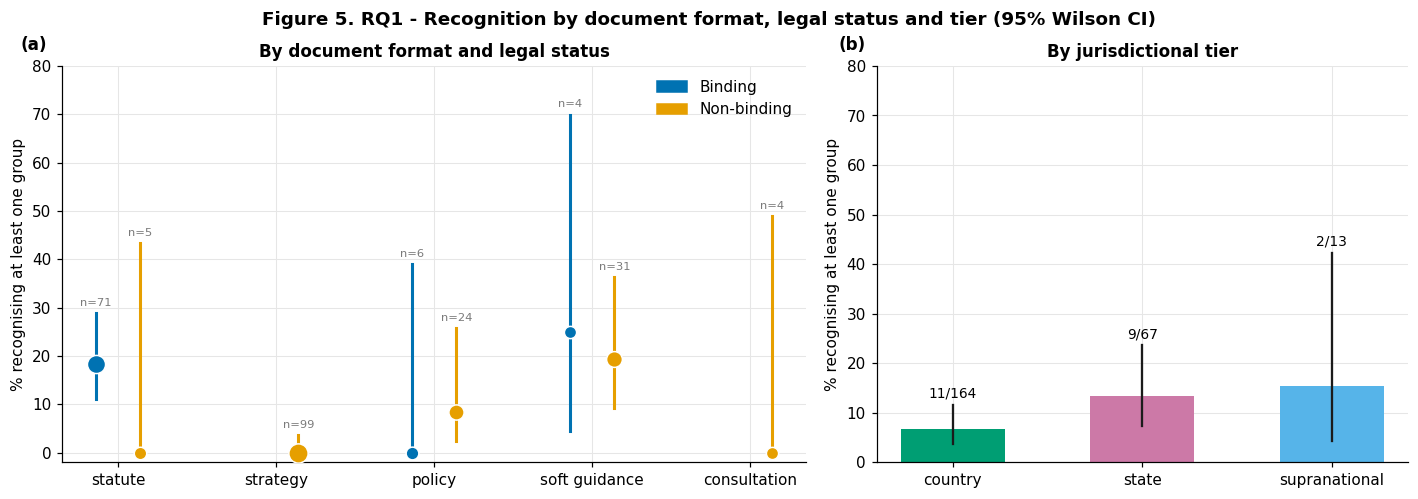

In [6]:
N = len(pol)
rows = []
for g in GROUPS:
    v = pol[f"grp_{g}"]; rec = int((v > 0).sum()); pas = int((v == 1).sum()); act = int((v >= 2).sum())
    lo, hi = wilson(rec, N)
    rows.append({"stakeholder_group": GROUP_LABEL[g], "n_recognised": rec, "pct_of_policies": round(100 * rec / N, 1),
                 "ci_low": round(100 * lo, 1), "ci_high": round(100 * hi, 1), "passive": pas,
                 "procedural": int((v == 2).sum()), "explicit_right_remedy": int((v == 3).sum()), "active_(>=2)": act,
                 "active_to_passive_ratio": round(act / pas, 2) if pas else np.nan,
                 "pct_active_of_recognised": round(100 * act / rec, 1) if rec else np.nan})
rq1 = pd.DataFrame(rows).set_index("stakeholder_group")
show(rq1, "Table 8. RQ1 - Recognition and protection depth by stakeholder group (reconciled coding)", "t08_rq1_recognition_by_group")

breadth = pd.Series({"policies_with_any_group_%": round(100 * pol["inclusion"].mean(), 1),
                     "mean_groups_per_policy": round(pol["n_groups"].mean(), 3),
                     "mean_groups_per_recognising_policy": round(pol.loc[pol["inclusion"] == 1, "n_groups"].mean(), 2) if pol["inclusion"].sum() else np.nan,
                     "policies_with_>=2_groups": int((pol["n_groups"] >= 2).sum())})
show(breadth, "Breadth of representation", None)

# ---- binding vs non-binding by group
b1, b2 = "binding (hard law)", "non-binding (soft law)"
rows = []
for g in GROUPS:
    pol["_flag"] = (pol[f"grp_{g}"] > 0).astype(int)
    r = compare_binary(pol, "_flag", "law_type", b1, b2); r["stakeholder_group"] = GROUP_LABEL[g]; rows.append(r)
pol["_flag"] = pol["inclusion"]; r = compare_binary(pol, "_flag", "law_type", b1, b2); r["stakeholder_group"] = "Any group"; rows.append(r)
pol.drop(columns="_flag", inplace=True)
rq1_bind = pd.DataFrame(rows).set_index("stakeholder_group").rename(columns={
    "n_g1": "n_binding", "events_g1": "recognising_binding", "pct_g1": "pct_binding",
    "n_g2": "n_nonbinding", "events_g2": "recognising_nonbinding", "pct_g2": "pct_nonbinding"})
show(rq1_bind, "Table 9. RQ1 - Recognition in binding versus non-binding documents (odds ratio binding vs non-binding; Fisher exact)",
     "t09_rq1_binding_vs_nonbinding_by_group")

# ---- inclusion by format, tier and legal status
rows = []
for var in ["law_type", "format", "tier"]:
    ct = pd.crosstab(pol[var], pol["inclusion"])
    if ct.shape == (2, 2):
        p_overall = stats.fisher_exact(ct.values)[1]
    elif ct.shape[0] > 1 and ct.shape[1] > 1:
        p_overall = stats.chi2_contingency(ct)[1]
    else:
        p_overall = np.nan
    for cat, sub in pol.groupby(var):
        k, n = int(sub["inclusion"].sum()), len(sub); lo, hi = wilson(k, n)
        rows.append({"variable": var, "category": cat, "n_policies": n, "n_recognising": k, "pct": round(100 * k / n, 1),
                     "ci_low": round(100 * lo, 1), "ci_high": round(100 * hi, 1),
                     "mean_groups": round(sub["n_groups"].mean(), 3), "overall_test_p": p_overall})
inc_tbl = pd.DataFrame(rows)
show(inc_tbl, "Table 10. RQ1 - Recognition by legal status, format and tier (Fisher/chi-square p per variable; sparse cells: descriptive)",
     "t10_rq1_inclusion_by_format_tier_law", index=False)

# ---- group x jurisdiction heat table
jur_n = pol["jurisdiction"].value_counts()
top_j = jur_n[jur_n >= MIN_DOCS].index[:15]
heat = pd.DataFrame({j: {GROUP_LABEL[g]: 100 * (pol.loc[pol["jurisdiction"] == j, f"grp_{g}"] > 0).mean() for g in GROUPS}
                     for j in top_j}).T.round(1)
heat.insert(0, "n_policies", [int(jur_n[j]) for j in heat.index])
show(heat, f"Table 11. RQ1 - % of each jurisdiction's policies recognising each group (jurisdictions with >= {MIN_DOCS} policies, top 15)",
     "t11_rq1_group_by_jurisdiction")

# ---- Figure 3
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1.1, 1.2]})
ax = axes[0]; yy = np.arange(len(GROUPS))[::-1]
for yi, (name, r), col in zip(yy, rq1.iterrows(), GROUP_COL):
    ax.barh(yi, r["pct_of_policies"], color=col, height=0.6)
    ax.plot([r["ci_low"], r["ci_high"]], [yi, yi], color=PAL["ink"], lw=1.4)
    ax.text(r["ci_high"] + 0.4, yi, f"{int(r['n_recognised'])}", va="center", fontsize=9)
ax.set_yticks(yy); ax.set_yticklabels(rq1.index); ax.set_xlabel("% of policy documents recognising the group (95% Wilson CI; n labelled)")
ax.set_title("Breadth of representation"); panel(ax, "a")
ax = axes[1]; left = np.zeros(len(GROUPS))
for col_, lab, c in [("passive", "Passive", LEVEL_COL["passive"]), ("procedural", "Procedural safeguard", LEVEL_COL["procedural"]),
                     ("explicit_right_remedy", "Explicit right/remedy", LEVEL_COL["explicit"])]:
    ax.barh(yy, rq1[col_].values, left=left, color=c, label=lab, height=0.6, edgecolor="white"); left += rq1[col_].values
ax.set_yticks(yy); ax.set_yticklabels([]); ax.set_xlabel("Policy documents (count)"); ax.legend(loc="lower right")
ax.set_title("Depth: passive versus active"); panel(ax, "b")
ax = axes[2]
for yi, name in zip(yy, rq1.index):
    rr = rq1_bind.loc[name]
    ax.plot([rr["pct_nonbinding"], rr["pct_binding"]], [yi, yi], color="#bdbdbd", lw=3, zorder=1)
    ax.scatter(rr["pct_binding"], yi, s=90, color=LAW_COL[b1], zorder=3, edgecolor="white")
    ax.scatter(rr["pct_nonbinding"], yi, s=90, color=LAW_COL[b2], zorder=3, edgecolor="white")
ax.set_yticks(yy); ax.set_yticklabels([]); ax.set_xlabel("% of documents in the legal-status group recognising the group")
ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=LAW_COL[b1], markersize=9, label="Binding"),
                   Line2D([0], [0], marker="o", color="w", markerfacecolor=LAW_COL[b2], markersize=9, label="Non-binding")], loc="lower right")
ax.set_title("Binding versus non-binding"); panel(ax, "c")
plt.tight_layout(); savefig("fig03_rq1_representation_by_group", "Figure 3. RQ1 - Representation of stakeholder groups in AI policy documents")

# ---- Figure 4: heat map
if len(heat):
    hm = heat.drop(columns="n_policies")
    fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(hm) + 2.3))
    im = ax.imshow(hm.values.astype(float), cmap="YlGnBu", aspect="auto", vmin=0)
    ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns, rotation=25, ha="right")
    ax.set_yticks(range(len(hm))); ax.set_yticklabels([f"{j} (n={heat.loc[j, 'n_policies']})" for j in hm.index])
    ax.grid(False)
    for i in range(hm.shape[0]):
        for k in range(hm.shape[1]):
            v = hm.iat[i, k]; ax.text(k, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 0.55 * np.nanmax(hm.values) else PAL["ink"])
    plt.colorbar(im, ax=ax, label="% of the jurisdiction's policies recognising the group")
    plt.tight_layout(); savefig("fig04_rq1_group_by_jurisdiction_heatmap", "Figure 4. RQ1 - Recognition by stakeholder group and jurisdiction")

# ---- Figure 5: recognition by format x legal status and by tier
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
fmts = [f for f in ["statute", "strategy", "policy", "soft_guidance", "consultation", "other"] if f in pol["format"].unique()]
for j, (lt, c) in enumerate(LAW_COL.items()):
    for i, f in enumerate(fmts):
        sub = pol[(pol["format"] == f) & (pol["law_type"] == lt)]
        if len(sub) == 0: continue
        k, n = int(sub["inclusion"].sum()), len(sub); lo, hi = wilson(k, n); x = i + (j - 0.5) * 0.28
        ax1.plot([x, x], [100 * lo, 100 * hi], color=c, lw=2); ax1.scatter(x, 100 * k / n, s=40 + 3 * np.sqrt(n) * 4, color=c, edgecolor="white", zorder=3)
        ax1.text(x, 100 * hi + 1.5, f"n={n}", ha="center", fontsize=7.5, color=PAL["grey"])
ax1.set_xticks(range(len(fmts))); ax1.set_xticklabels([f.replace("_", " ") for f in fmts]); ax1.set_ylabel("% recognising at least one group"); ax1.set_ylim(-2, 80)
ax1.set_title("By document format and legal status"); ax1.legend(handles=[Patch(color=v, label=k.split(" ")[0].capitalize()) for k, v in LAW_COL.items()]); panel(ax1, "a")
tiers = [t for t in ["country", "state", "supranational"] if t in pol["tier"].unique()]
for i, t in enumerate(tiers):
    sub = pol[pol["tier"] == t]; k, n = int(sub["inclusion"].sum()), len(sub); lo, hi = wilson(k, n)
    ax2.bar(i, 100 * k / n, color=[PAL["green"], PAL["pink"], PAL["sky"]][i % 3], width=0.55)
    ax2.plot([i, i], [100 * lo, 100 * hi], color=PAL["ink"], lw=1.5); ax2.text(i, 100 * hi + 1.5, f"{k}/{n}", ha="center", fontsize=9)
ax2.set_xticks(range(len(tiers))); ax2.set_xticklabels(tiers); ax2.set_ylabel("% recognising at least one group"); ax2.set_ylim(0, 80)
ax2.set_title("By jurisdictional tier"); panel(ax2, "b")
plt.tight_layout(); savefig("fig05_rq1_recognition_by_format_tier", "Figure 5. RQ1 - Recognition by document format, legal status and tier (95% Wilson CI)")

## 6. RQ2: To what extent do AI policies translate stakeholder recognition into clearly defined rights, protections and obligations?
**What this cell does.** Follows the proposal's **recognition-to-enforceability funnel** and compares binding with non-binding instruments.
* **Funnel (documents):** all policies → recognise ≥1 group → ≥1 group with a procedural safeguard or explicit right → ≥1 group with an explicit right/remedy.
* **Conversion rate (group level):** the share of recognised group-document pairs that obtain a procedural safeguard (score ≥ 2) or an explicit right (score 3).
* **Binding versus non-binding:** for each indicator the counts, percentages, odds ratio (with Haldane–Anscombe correction for zero cells) and Fisher's exact test; the accountability index is compared with a Mann–Whitney test.
* **Obligation profile:** the mix of obligation categories in binding versus non-binding obligations, a chi-square test across all categories (flagged when expected counts are sparse) and a Fisher test for ten accountability-related categories.

**Figures.** *Figure 6* (a) funnel, (b) protection level of recognised groups. *Figure 7* dumbbell plot of binding versus non-binding indicators with significance stars. *Figure 8* obligation categories by binding status.

**How to read it.** A steep funnel means recognition seldom turns into stated rights; stars mark Fisher p < 0.05 (*), < 0.01 (**), < 0.001 (***), computed on a small corpus and not corrected for multiple tests.

**Outputs.** `t12`–`t16` CSV files and `fig06`–`fig08` PDFs.

**Table 12. RQ2 - Stakeholder-linked recognition-to-protection funnel (policy documents)**

,stage,n_policies,pct_of_all,pct_of_previous_stage
0,All policy documents,244,100.0,NaN
1,Recognise at least one stakeholder group,22,9.0,9.0
2,Recognition linked to procedural protection or explicit right,10,4.1,45.5
3,Recognition linked to explicit individual right/remedy,0,0.0,0.0


**RQ2 distinction: document-level versus stakeholder-linked mechanisms**

,measure,n_policies,pct_of_all_policies
0,Any document-level procedural or explicit mechanism,28,11.5
1,Any document-level explicit right/remedy,1,0.4
2,Stakeholder-linked procedural or explicit protection,10,4.1
3,Stakeholder-linked explicit right/remedy,0,0.0


**Table 13. RQ2 - Recognition-to-protection conversion rate by stakeholder group (group-document pairs)**

,recognised,passive,procedural,explicit,conversion_rate_procedural_or_explicit_%,explicit_rate_%
stakeholder_group,,,,,,
Consumers / individuals,11,5,6,0,54.5,0.0
Workers,11,7,4,0,36.4,0.0
Children,2,1,1,0,50.0,0.0
Vulnerable groups,0,0,0,0,NaN,NaN
Civil society,1,1,0,0,0.0,0.0
All groups,25,14,11,0,44.0,0.0


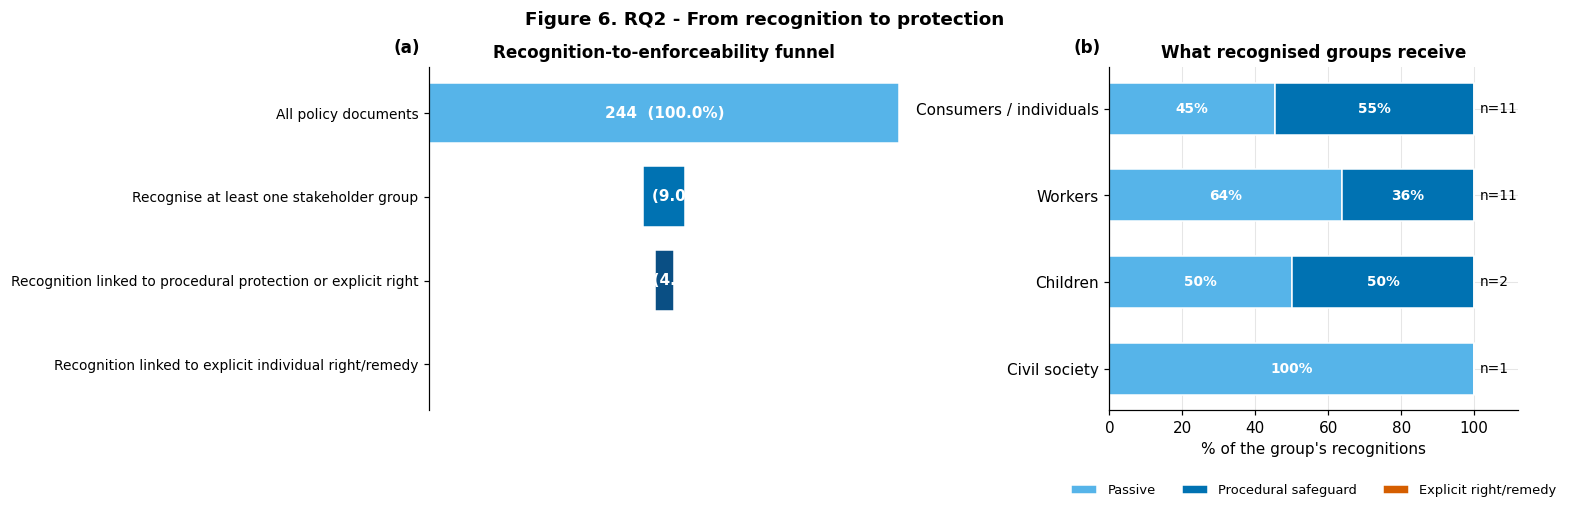

**Table 14. RQ2 - Binding versus non-binding documents: indicators, odds ratio (binding vs non-binding) and Fisher exact p**

,n_binding,n_with_indicator_binding,pct_binding,n_nonbinding,n_with_indicator_nonbinding,pct_nonbinding,odds_ratio,OR_CI_low,OR_CI_high,fisher_p,variable
indicator,,,,,,,,,,,
Stakeholder recognition (any group),81,14,17.3,163,8,4.9,4.05,1.62,10.11,3.305374e-03,inclusion
Right / protection for a group (score >= 2),81,8,9.9,163,2,1.2,8.82,1.83,42.57,2.743189e-03,f_right_protection
Document-level procedural safeguard (not necessarily stakeholder-linked),81,19,23.5,163,8,4.9,5.94,2.47,14.27,3.973807e-05,procedural_protection
Document-level explicit right/remedy (not necessarily stakeholder-linked),81,0,0.0,163,1,0.6,0.66,0.03,16.50,1.000000e+00,enforceable_remedy
Document-level procedural or explicit mechanism (>= 2),81,19,23.5,163,9,5.5,5.24,2.25,12.22,7.647457e-05,procedural_or_enforceable
Public-enforcement reference,81,4,4.9,163,1,0.6,8.42,0.92,76.57,4.291625e-02,public_enforcement
Duty-holder identified,81,28,34.6,163,10,6.1,8.08,3.68,17.75,2.885374e-08,f_duty_holder
Oversight and enforcement,81,30,37.0,163,29,17.8,2.72,1.49,4.97,1.408149e-03,f_oversight_enforcement
Implementation support,81,16,19.8,163,30,18.4,1.09,0.56,2.14,8.623927e-01,f_implementation_support


Accountability index (0-5): binding mean 1.25, non-binding mean 0.49; Mann-Whitney U = 9382, p = 2.467e-09


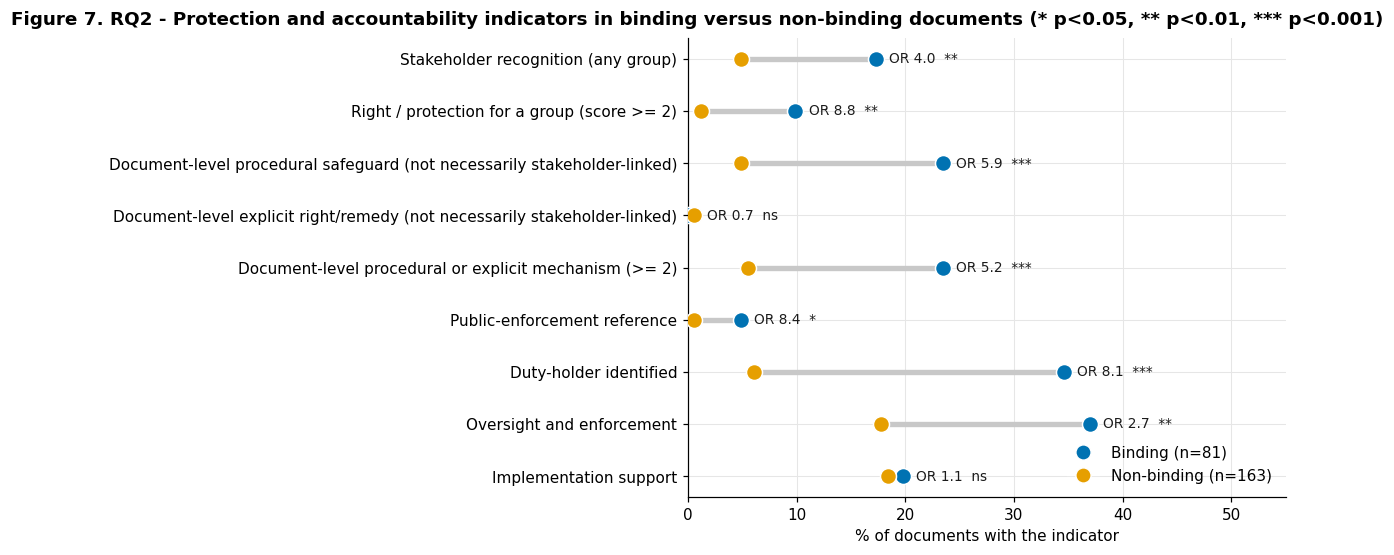

**Table 15. RQ2 - Obligation categories by binding status (chi-square p = 0.31; sparse expected counts; descriptive)**

,non-binding,binding,non-binding_%,binding_%
category,,,,
transparency,2,23,10.0,23.7
governance_accountability,8,11,40.0,11.3
incident_handling,0,7,0.0,7.2
prohibited_practice,0,6,0.0,6.2
risk_management,2,6,10.0,6.2
human_oversight,3,6,15.0,6.2
privacy_data_protection,0,5,0.0,5.2
impact_assessment,2,5,10.0,5.2
technical_documentation,0,5,0.0,5.2


**Table 16. RQ2 - Accountability-related obligation categories by binding status (Fisher exact p = 0.0488, odds ratio binding vs non-binding = 0.33)**

,n_accountability_obligations,n_obligations,share_%
binding,48,97,49.5
non-binding,15,20,75.0


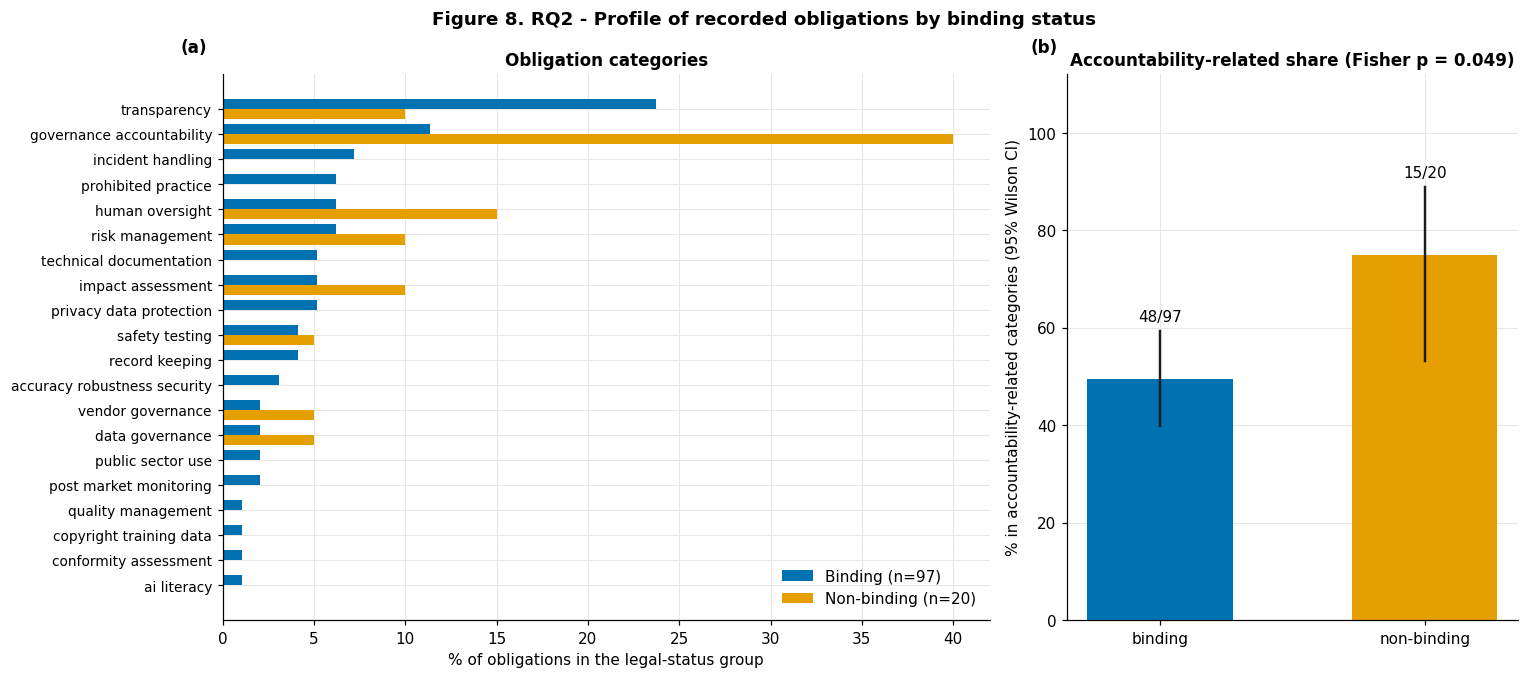

In [7]:
gcols = [f"grp_{g}" for g in GROUPS]
stages = [("All policy documents", N),
          ("Recognise at least one stakeholder group", int(pol["inclusion"].sum())),
          ("Recognition linked to procedural protection or explicit right", int((pol[gcols] >= 2).any(axis=1).sum())),
          ("Recognition linked to explicit individual right/remedy", int((pol[gcols] == 3).any(axis=1).sum()))]
funnel = pd.DataFrame(stages, columns=["stage", "n_policies"])
funnel["pct_of_all"] = (100 * funnel["n_policies"] / N).round(1)
funnel["pct_of_previous_stage"] = (100 * funnel["n_policies"] / funnel["n_policies"].shift(1)).round(1)
show(funnel, "Table 12. RQ2 - Stakeholder-linked recognition-to-protection funnel (policy documents)", "t12_rq2_funnel", index=False)

# Keep document-level remedy measures separate: these may occur without a named
# stakeholder being connected to the remedy.
doc_level_remedy_summary = pd.DataFrame([
    ["Any document-level procedural or explicit mechanism", int(pol["procedural_or_enforceable"].sum())],
    ["Any document-level explicit right/remedy", int(pol["enforceable_remedy"].sum())],
    ["Stakeholder-linked procedural or explicit protection", int((pol[gcols] >= 2).any(axis=1).sum())],
    ["Stakeholder-linked explicit right/remedy", int((pol[gcols] == 3).any(axis=1).sum())]
], columns=["measure", "n_policies"])
doc_level_remedy_summary["pct_of_all_policies"] = (100 * doc_level_remedy_summary["n_policies"] / N).round(1)
show(doc_level_remedy_summary, "RQ2 distinction: document-level versus stakeholder-linked mechanisms",
     "t12b_rq2_document_vs_stakeholder_linked", index=False)

rows = []
for g in GROUPS:
    v = pol[f"grp_{g}"]; rec = int((v > 0).sum())
    rows.append({"stakeholder_group": GROUP_LABEL[g], "recognised": rec, "passive": int((v == 1).sum()),
                 "procedural": int((v == 2).sum()), "explicit": int((v == 3).sum())})
conv = pd.DataFrame(rows).set_index("stakeholder_group")
conv.loc["All groups"] = conv.sum()
conv["conversion_rate_procedural_or_explicit_%"] = (100 * (conv["procedural"] + conv["explicit"]) / conv["recognised"].replace(0, np.nan)).round(1)
conv["explicit_rate_%"] = (100 * conv["explicit"] / conv["recognised"].replace(0, np.nan)).round(1)
show(conv, "Table 13. RQ2 - Recognition-to-protection conversion rate by stakeholder group (group-document pairs)", "t13_rq2_conversion_rate")

# ---- Figure 6
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
mx = funnel["n_policies"].max(); cols = [PAL["sky"], PAL["blue"], "#0a4f84", PAL["red"]]
for i, r in enumerate(funnel.itertuples()):
    ax1.barh(-i, r.n_policies, left=(mx - r.n_policies) / 2, color=cols[i], height=0.72, edgecolor="white")
    ax1.text(mx / 2, -i, f"{r.n_policies}  ({r.pct_of_all}%)", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
ax1.set_yticks([-i for i in range(len(funnel))]); ax1.set_yticklabels([s.replace(" with ", "\nwith ") for s in funnel["stage"]], fontsize=9)
ax1.set_xlim(0, mx); ax1.set_xticks([]); ax1.grid(False); ax1.spines["bottom"].set_visible(False); ax1.set_title("Recognition-to-enforceability funnel"); panel(ax1, "a")
cc = conv.drop(index="All groups"); cc = cc[cc["recognised"] > 0]; yy = np.arange(len(cc))[::-1]; left = np.zeros(len(cc))
for col_, lab, c in [("passive", "Passive", LEVEL_COL["passive"]), ("procedural", "Procedural safeguard", LEVEL_COL["procedural"]), ("explicit", "Explicit right/remedy", LEVEL_COL["explicit"])]:
    v = 100 * cc[col_].values / cc["recognised"].values
    ax2.barh(yy, v, left=left, color=c, label=lab, height=0.6, edgecolor="white")
    for yi, vi, li in zip(yy, v, left):
        if vi >= 8: ax2.text(li + vi / 2, yi, f"{vi:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += v
for yi, n in zip(yy, cc["recognised"]): ax2.text(101.5, yi, f"n={n}", va="center", fontsize=9)
ax2.set_yticks(yy); ax2.set_yticklabels(cc.index); ax2.set_xlim(0, 112); ax2.set_xlabel("% of the group's recognitions")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8.5); ax2.set_title("What recognised groups receive"); panel(ax2, "b")
plt.tight_layout(); savefig("fig06_rq2_funnel_and_conversion", "Figure 6. RQ2 - From recognition to protection")

# ---- binding vs non-binding indicators
OUTCOMES = [("inclusion", "Stakeholder recognition (any group)"), ("f_right_protection", "Right / protection for a group (score >= 2)"),
            ("procedural_protection", "Document-level procedural safeguard (not necessarily stakeholder-linked)"), ("enforceable_remedy", "Document-level explicit right/remedy (not necessarily stakeholder-linked)"),
            ("procedural_or_enforceable", "Document-level procedural or explicit mechanism (>= 2)"), ("public_enforcement", "Public-enforcement reference"),
            ("f_duty_holder", "Duty-holder identified"), ("f_oversight_enforcement", "Oversight and enforcement"),
            ("f_implementation_support", "Implementation support")]
rows = []
for var, lab in OUTCOMES:
    r = compare_binary(pol, var, "law_type", b1, b2); r["indicator"] = lab; r["variable"] = var; rows.append(r)
comp = pd.DataFrame(rows).set_index("indicator").rename(columns={
    "n_g1": "n_binding", "events_g1": "n_with_indicator_binding", "pct_g1": "pct_binding",
    "n_g2": "n_nonbinding", "events_g2": "n_with_indicator_nonbinding", "pct_g2": "pct_nonbinding"})
bb = pol.loc[pol["law_type"] == b1, "accountability_index"]; nn = pol.loc[pol["law_type"] == b2, "accountability_index"]
u, p_mw = stats.mannwhitneyu(bb, nn, alternative="two-sided")
show(comp, "Table 14. RQ2 - Binding versus non-binding documents: indicators, odds ratio (binding vs non-binding) and Fisher exact p",
     "t14_rq2_binding_vs_nonbinding")
print(f"Accountability index (0-5): binding mean {bb.mean():.2f}, non-binding mean {nn.mean():.2f}; Mann-Whitney U = {u:.0f}, p = {p_mw:.4g}")

def stars(p): return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"
fig, ax = plt.subplots(figsize=(11, 4.9)); yy = np.arange(len(comp))[::-1]
for yi, (lab, r) in zip(yy, comp.iterrows()):
    ax.plot([r["pct_nonbinding"], r["pct_binding"]], [yi, yi], color="#c8c8c8", lw=3.5, zorder=1)
    ax.scatter(r["pct_binding"], yi, s=110, color=LAW_COL[b1], zorder=3, edgecolor="white")
    ax.scatter(r["pct_nonbinding"], yi, s=110, color=LAW_COL[b2], zorder=3, edgecolor="white")
    ax.text(max(r["pct_binding"], r["pct_nonbinding"]) + 1.2, yi, f"OR {r['odds_ratio']:.1f}  {stars(r['fisher_p'])}", va="center", fontsize=9, color=PAL["ink"])
ax.set_yticks(yy); ax.set_yticklabels(comp.index); ax.set_xlabel("% of documents with the indicator"); ax.set_xlim(0, max(comp[["pct_binding", "pct_nonbinding"]].max()) + 18)
ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=LAW_COL[b1], markersize=10, label=f"Binding (n={int(comp['n_binding'].iloc[0])})"),
                   Line2D([0], [0], marker="o", color="w", markerfacecolor=LAW_COL[b2], markersize=10, label=f"Non-binding (n={int(comp['n_nonbinding'].iloc[0])})")], loc="lower right")
plt.tight_layout(); savefig("fig07_rq2_binding_vs_nonbinding", "Figure 7. RQ2 - Protection and accountability indicators in binding versus non-binding documents (* p<0.05, ** p<0.01, *** p<0.001)")

# ---- obligation profile by binding status
cat_ct = pd.crosstab(obl["category"], obl["is_binding"]).reindex(columns=[False, True], fill_value=0)
cat_ct.columns = ["non-binding", "binding"]
cat_share = (100 * cat_ct / cat_ct.sum()).round(1).add_suffix("_%")
cat_tbl = pd.concat([cat_ct, cat_share], axis=1).sort_values("binding", ascending=False)
chi2, p_chi, dof, expected = stats.chi2_contingency(cat_ct.values)
sparse_note = "sparse expected counts; descriptive" if (expected < 5).any() else "expected counts adequate"
show(cat_tbl, f"Table 15. RQ2 - Obligation categories by binding status (chi-square p = {p_chi:.3g}; {sparse_note})", "t15_rq2_obligation_profile")

ACCOUNTABILITY_CATEGORIES = ["governance_accountability", "human_oversight", "risk_management", "impact_assessment", "incident_handling",
                             "record_keeping", "post_market_monitoring", "conformity_assessment", "quality_management", "technical_documentation"]
obl["accountability_category"] = obl["category"].isin(ACCOUNTABILITY_CATEGORIES)
acc = obl.groupby("is_binding")["accountability_category"].agg(["sum", "count"]).reindex([True, False])
acc.index = ["binding", "non-binding"]; acc.columns = ["n_accountability_obligations", "n_obligations"]
acc["share_%"] = (100 * acc["n_accountability_obligations"] / acc["n_obligations"]).round(1)
table = [[int(acc.loc["binding", "n_accountability_obligations"]), int(acc.loc["binding", "n_obligations"] - acc.loc["binding", "n_accountability_obligations"])],
         [int(acc.loc["non-binding", "n_accountability_obligations"]), int(acc.loc["non-binding", "n_obligations"] - acc.loc["non-binding", "n_accountability_obligations"])]]
o_acc, p_acc = stats.fisher_exact(table)
show(acc, f"Table 16. RQ2 - Accountability-related obligation categories by binding status (Fisher exact p = {p_acc:.3g}, odds ratio binding vs non-binding = {o_acc:.2f})", "t16_rq2_accountability_categories")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.7, 1]})
plot = (100 * cat_ct / cat_ct.sum()).sort_values("binding"); yy = np.arange(len(plot)); h = 0.4
ax1.barh(yy + h / 2, plot["binding"], height=h, color=LAW_COL[b1], label=f"Binding (n={int(cat_ct['binding'].sum())})")
ax1.barh(yy - h / 2, plot["non-binding"], height=h, color=LAW_COL[b2], label=f"Non-binding (n={int(cat_ct['non-binding'].sum())})")
ax1.set_yticks(yy); ax1.set_yticklabels([c.replace("_", " ") for c in plot.index], fontsize=9); ax1.set_xlabel("% of obligations in the legal-status group")
ax1.legend(loc="lower right"); ax1.set_title("Obligation categories"); panel(ax1, "a")
for i, (lab, r) in enumerate(acc.iterrows()):
    k, n = int(r["n_accountability_obligations"]), int(r["n_obligations"]); lo, hi = wilson(k, n)
    ax2.bar(i, 100 * k / n, color=LAW_COL[b1 if lab == "binding" else b2], width=0.55)
    ax2.plot([i, i], [100 * lo, 100 * hi], color=PAL["ink"], lw=1.6); ax2.text(i, 100 * hi + 2, f"{k}/{n}", ha="center", fontsize=10)
ax2.set_xticks([0, 1]); ax2.set_xticklabels(acc.index); ax2.set_ylim(0, 112); ax2.set_ylabel("% in accountability-related categories (95% Wilson CI)")
ax2.set_title(f"Accountability-related share (Fisher p = {p_acc:.3f})"); panel(ax2, "b")
plt.tight_layout(); savefig("fig08_rq2_obligation_profile", "Figure 8. RQ2 - Profile of recorded obligations by binding status")

## 7. RQ3: What accountability mechanisms (oversight, enforcement and remedies) are established to support compliance?
### 7a. Remedy levels, accountability features, co-occurrence and the accountability index
**What this cell does.**
* **Remedy levels** (0 none, 1 symbolic, 2 procedural, 3 explicit right/remedy) by legal status and by format × legal status.
* **Five accountability features** from the codebook (right/protection, duty-holder, oversight and enforcement, complaint and remedy, implementation support): prevalence in binding versus non-binding documents.
* **Co-occurrence matrix:** of the documents showing the row feature, the share that also show the column feature (shows which mechanisms appear together).
* **Accountability index (0–5):** the number of features present in a document, compared by legal status (Mann–Whitney), format and tier (Kruskal–Wallis).

**Figures.** *Figure 9* (a) remedy-level distribution by legal status, (b) mean remedy score by format and legal status with the number of documents. *Figure 10* (a) feature prevalence, (b) co-occurrence heat map, (c) accountability index by tier and legal status.

**How to read it.** A document can contain a duty-holder and an oversight body but no complaint or remedy route; the co-occurrence matrix makes such partial accountability visible. The index is exploratory: two of its features (duty-holder, implementation support) come from keyword rules that have not been validated by human coders.

**Outputs.** `t17`–`t20` CSV files, `fig09`, `fig10` PDFs.

**Table 17. RQ3 - Document-level remedy level by legal status (counts and row %)**

,0 None,1 Symbolic,2 Procedural,3 Explicit right/remedy,0 None (%),1 Symbolic (%),2 Procedural (%),3 Explicit right/remedy (%)
law_type,,,,,,,,
binding (hard law),36,26,19,0,44.4,32.1,23.5,0.0
non-binding (soft law),53,101,8,1,32.5,62.0,4.9,0.6


**Table 18. RQ3 - Prevalence of the five accountability features**

,all_n,all_%,binding_%,nonbinding_%
Right / protection,10.0,4.1,9.9,1.2
Duty-holder,38.0,15.6,34.6,6.1
Oversight & enforcement,59.0,24.2,37.0,17.8
Complaint & remedy,28.0,11.5,23.5,5.5
Implementation support,46.0,18.9,19.8,18.4


**Table 19. RQ3 - Co-occurrence of accountability features (% of documents with the row feature that also show the column feature)**

,Right / protection,Duty-holder,Oversight & enforcement,Complaint & remedy,Implementation support
Right / protection,100.0,70.0,60.0,100.0,60.0
Duty-holder,18.4,100.0,42.1,31.6,28.9
Oversight & enforcement,10.2,27.1,100.0,27.1,37.3
Complaint & remedy,35.7,42.9,57.1,100.0,39.3
Implementation support,13.0,23.9,47.8,23.9,100.0


**Table 20. RQ3 - Accountability index (0-5) by legal status, format and tier (Mann-Whitney for 2 groups, Kruskal-Wallis otherwise)**

,variable,category,n_policies,mean_index,median_index,pct_index_>=3,test_p
0,law_type,binding (hard law),81,1.25,1.0,11.1,2.466841e-09
1,law_type,non-binding (soft law),163,0.49,0.0,3.7,2.466841e-09
2,format,consultation,4,1.25,1.0,25.0,4.228893e-16
3,format,policy,30,0.60,0.0,6.7,4.228893e-16
4,format,soft_guidance,35,1.20,1.0,8.6,4.228893e-16
5,format,statute,76,1.33,1.0,11.8,4.228893e-16
6,format,strategy,99,0.15,0.0,0.0,4.228893e-16
7,tier,country,164,0.64,0.0,4.9,7.930064e-02
8,tier,state,67,0.93,1.0,7.5,7.930064e-02
9,tier,supranational,13,1.08,0.0,15.4,7.930064e-02


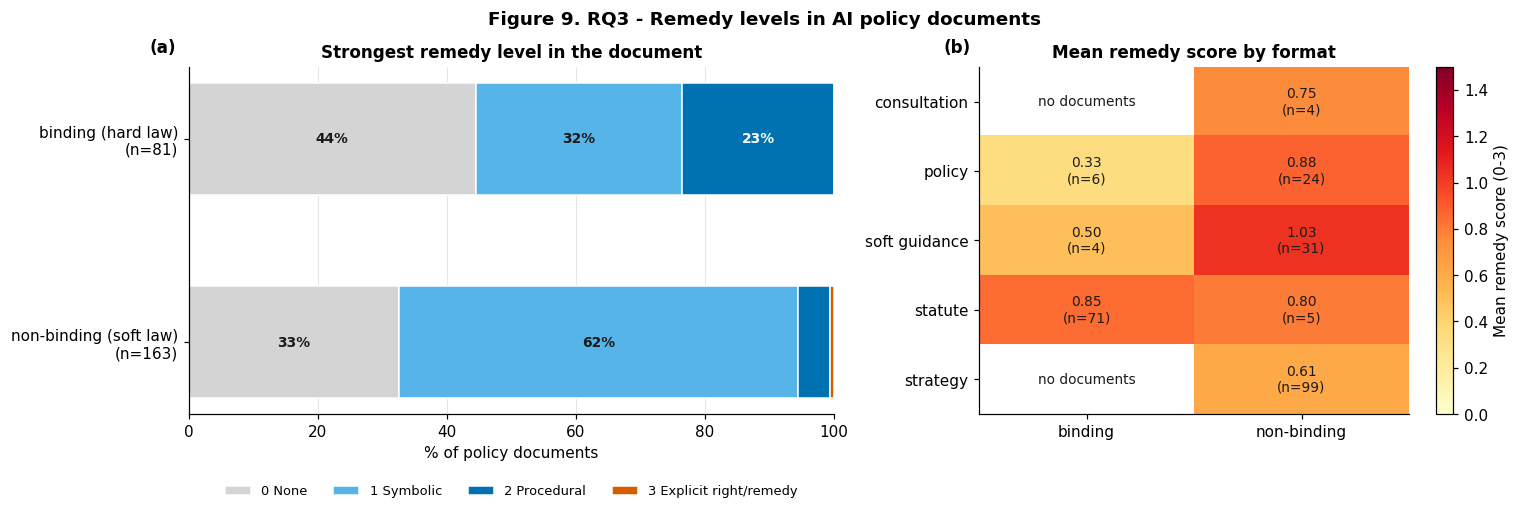

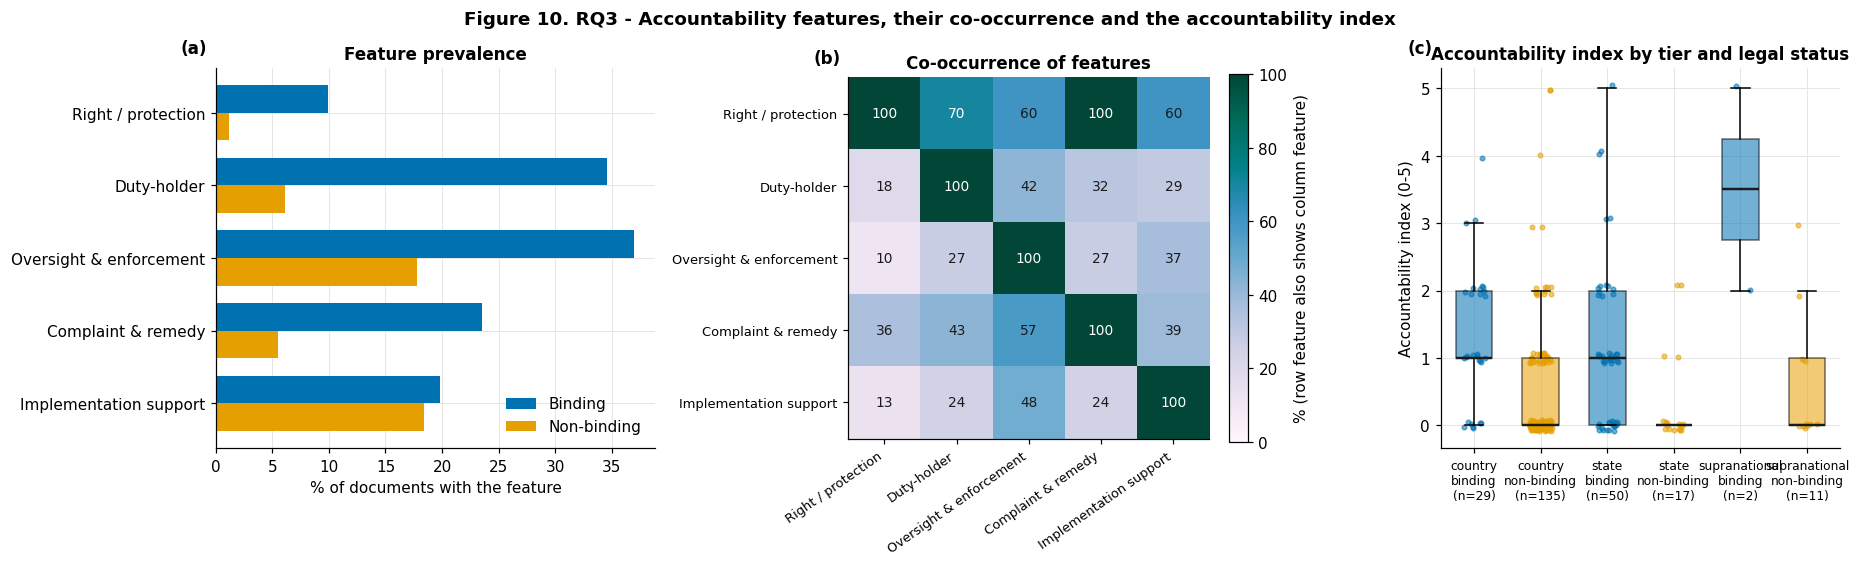

In [8]:
# ---- remedy level distribution
rem_ct = pd.crosstab(pol["law_type"], pol["remedy"]).reindex(columns=[0, 1, 2, 3], fill_value=0)
rem_ct.columns = REMEDY_LAB
rem_pct = (100 * rem_ct.div(rem_ct.sum(axis=1), axis=0)).round(1).add_suffix(" (%)")
show(pd.concat([rem_ct, rem_pct], axis=1), "Table 17. RQ3 - Document-level remedy level by legal status (counts and row %)", "t17_rq3_remedy_distribution")

# ---- feature prevalence and co-occurrence
feat_cols = [f"f_{f}" for f in FEATURES]
prev = pd.DataFrame({FEATURE_LABEL[f]: {"all_n": int(pol[f"f_{f}"].sum()), "all_%": round(100 * pol[f"f_{f}"].mean(), 1),
                                        "binding_%": round(100 * pol.loc[pol["is_binding"], f"f_{f}"].mean(), 1),
                                        "nonbinding_%": round(100 * pol.loc[~pol["is_binding"], f"f_{f}"].mean(), 1)} for f in FEATURES}).T
show(prev, "Table 18. RQ3 - Prevalence of the five accountability features", "t18_rq3_feature_prevalence")

co = pd.DataFrame(index=[FEATURE_LABEL[f] for f in FEATURES], columns=[FEATURE_LABEL[f] for f in FEATURES], dtype=float)
for f1 in FEATURES:
    den = pol[f"f_{f1}"].sum()
    for f2 in FEATURES:
        co.loc[FEATURE_LABEL[f1], FEATURE_LABEL[f2]] = 100 * ((pol[f"f_{f1}"] == 1) & (pol[f"f_{f2}"] == 1)).sum() / den if den else np.nan
show(co.round(1), "Table 19. RQ3 - Co-occurrence of accountability features (% of documents with the row feature that also show the column feature)", "t19_rq3_feature_cooccurrence")

# ---- accountability index
rows = []
for var in ["law_type", "format", "tier"]:
    groups = [g["accountability_index"].values for _, g in pol.groupby(var)]
    p = stats.mannwhitneyu(groups[0], groups[1])[1] if len(groups) == 2 else (stats.kruskal(*groups)[1] if len(groups) > 2 else np.nan)
    for cat, sub in pol.groupby(var):
        rows.append({"variable": var, "category": cat, "n_policies": len(sub), "mean_index": round(sub["accountability_index"].mean(), 2),
                     "median_index": sub["accountability_index"].median(), "pct_index_>=3": round(100 * (sub["accountability_index"] >= 3).mean(), 1),
                     "test_p": p})
idx_tbl = pd.DataFrame(rows)
show(idx_tbl, "Table 20. RQ3 - Accountability index (0-5) by legal status, format and tier (Mann-Whitney for 2 groups, Kruskal-Wallis otherwise)",
     "t20_rq3_accountability_index", index=False)

# ---- Figure 9
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
pct = 100 * rem_ct.div(rem_ct.sum(axis=1), axis=0); yy = np.arange(len(pct))[::-1]; left = np.zeros(len(pct))
for k, (lab, c) in enumerate(zip(REMEDY_LAB, REMEDY_COL)):
    v = pct[lab].values; ax1.barh(yy, v, left=left, color=c, label=lab, height=0.55, edgecolor="white")
    for yi, vi, li in zip(yy, v, left):
        if vi >= 6: ax1.text(li + vi / 2, yi, f"{vi:.0f}%", ha="center", va="center", fontsize=9, color="white" if k >= 2 else PAL["ink"], fontweight="bold")
    left += v
ax1.set_yticks(yy); ax1.set_yticklabels([f"{i}\n(n={int(rem_ct.loc[i].sum())})" for i in pct.index]); ax1.set_xlabel("% of policy documents")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4, fontsize=8.5); ax1.set_title("Strongest remedy level in the document"); panel(ax1, "a")
piv = pol.pivot_table(index="format", columns="law_type", values="remedy", aggfunc="mean")
cnt = pol.pivot_table(index="format", columns="law_type", values="remedy", aggfunc="count")
im = ax2.imshow(piv.values.astype(float), cmap="YlOrRd", vmin=0, vmax=max(1.5, np.nanmax(piv.values)), aspect="auto")
ax2.set_xticks(range(piv.shape[1])); ax2.set_xticklabels([c.split(" ")[0] for c in piv.columns]); ax2.set_yticks(range(piv.shape[0])); ax2.set_yticklabels([i.replace("_", " ") for i in piv.index]); ax2.grid(False)
for i in range(piv.shape[0]):
    for k in range(piv.shape[1]):
        v, n = piv.iat[i, k], cnt.iat[i, k]
        ax2.text(k, i, "no documents" if pd.isna(v) else f"{v:.2f}\n(n={int(n)})", ha="center", va="center", fontsize=9, color="white" if (not pd.isna(v) and v > 1.3) else PAL["ink"])
plt.colorbar(im, ax=ax2, label="Mean remedy score (0-3)"); ax2.set_title("Mean remedy score by format"); panel(ax2, "b")
plt.tight_layout(); savefig("fig09_rq3_remedy_levels", "Figure 9. RQ3 - Remedy levels in AI policy documents")

# ---- Figure 10
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ax = axes[0]; yy = np.arange(len(FEATURES))[::-1]; h = 0.38
ax.barh(yy + h / 2, [prev.loc[FEATURE_LABEL[f], "binding_%"] for f in FEATURES], height=h, color=LAW_COL[b1], label="Binding")
ax.barh(yy - h / 2, [prev.loc[FEATURE_LABEL[f], "nonbinding_%"] for f in FEATURES], height=h, color=LAW_COL[b2], label="Non-binding")
ax.set_yticks(yy); ax.set_yticklabels([FEATURE_LABEL[f] for f in FEATURES]); ax.set_xlabel("% of documents with the feature"); ax.legend(loc="lower right"); ax.set_title("Feature prevalence"); panel(ax, "a")
ax = axes[1]; im = ax.imshow(co.values.astype(float), cmap="PuBuGn", vmin=0, vmax=100); ax.grid(False)
ax.set_xticks(range(5)); ax.set_xticklabels([FEATURE_LABEL[f] for f in FEATURES], rotation=35, ha="right", fontsize=8.5)
ax.set_yticks(range(5)); ax.set_yticklabels([FEATURE_LABEL[f] for f in FEATURES], fontsize=8.5)
for i in range(5):
    for k in range(5):
        v = co.values[i, k]; ax.text(k, i, "n/a" if pd.isna(v) else f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if (not pd.isna(v) and v > 60) else PAL["ink"])
plt.colorbar(im, ax=ax, label="% (row feature also shows column feature)", fraction=0.046); ax.set_title("Co-occurrence of features"); panel(ax, "b")
ax = axes[2]; order = [(t, lt) for t in ["country", "state", "supranational"] if t in pol["tier"].unique() for lt in LAW_COL]
data_, labs_, cols_ = [], [], []
for t, lt in order:
    v = pol.loc[(pol["tier"] == t) & (pol["law_type"] == lt), "accountability_index"].values
    if len(v): data_.append(v); labs_.append(f"{t}\n{lt.split(' ')[0]}\n(n={len(v)})"); cols_.append(LAW_COL[lt])
bp = ax.boxplot(data_, patch_artist=True, widths=0.55, medianprops=dict(color=PAL["ink"], lw=1.6), showfliers=False)
for patch, c in zip(bp["boxes"], cols_): patch.set_facecolor(c); patch.set_alpha(0.55)
for i, v in enumerate(data_, 1): ax.scatter(i + rng.uniform(-0.17, 0.17, len(v)), v + rng.uniform(-0.08, 0.08, len(v)), s=9, color=cols_[i - 1], alpha=0.55)
ax.set_xticks(range(1, len(labs_) + 1)); ax.set_xticklabels(labs_, fontsize=8); ax.set_ylabel("Accountability index (0-5)"); ax.set_title("Accountability index by tier and legal status"); panel(ax, "c")
plt.tight_layout(); savefig("fig10_rq3_features_and_index", "Figure 10. RQ3 - Accountability features, their co-occurrence and the accountability index")

### 7b. RQ3 regression models, odds ratios and predicted probabilities
**What this cell does.** Follows the proposal's **experimental design for the statistical model** (section 6.6):
* **Dependent variable:** *strong remedy* = remedy level ≥ 2 (a procedural or explicit remedy), binary; secondary outcome: ordered remedy level 0–3.
* **Predictors:** binding status, document format (reference: soft guidance) and tier (reference: country); stakeholder inclusion is added in model M2.
* **Models:** M1 (proposal specification), M2 (adds inclusion), M3 (inclusion only), M4 (explicit right/remedy, usually not estimable), M5 (binding instruments only), plus an **ordered logit** for the 0–3 score.
* **Safeguards:** logistic regression with **HC1 robust standard errors**, estimated only if there are at least `MIN_EVENTS` events *and* non-events, with convergence and separation checks. If a model fails because of quasi-separation, **categories are collapsed rather than dropped** (tier → country vs other; then also format → statute vs other), as the proposal specifies. A model that cannot be estimated is reported as *not estimated*, never forced.
* **Reported:** odds ratios with 95% CI, p-values, McFadden pseudo-R², likelihood-ratio test, and **predicted probabilities with 95% CI** (delta method, using the HC1 covariance matrix) by format and legal status.

**Figures.** *Figure 11* forest plot of adjusted odds ratios (M1 and M2). *Figure 12* predicted probability of a strong remedy by format and legal status.

**How to read it.** An odds ratio above 1 means higher odds of a strong remedy; a confidence interval that crosses 1 means the association is not distinguishable from no association in this sample. Binding status and statute format overlap strongly, so their separate effects are imprecise. Associations are not causal.

**Outputs.** `t21_rq3_model_overview.csv`, `t22_rq3_model_coefficients.csv`, `t23_rq3_predicted_probabilities.csv`, `t24_rq3_ordered_logit.csv`, `fig11`, `fig12`.

Complete-case N for regression: 244 | binding-only N: 81


**RQ3 diagnostic: format by legal status (inspect sparse/empty cells)**

binding,binding,non-binding
format3,,
soft_guidance,4,31
statute,71,5
strategy_policy,6,127


Interpretation warning: these are observational associations, not causal effects. Where format and legal status nearly determine one another, adjusted coefficients are unstable and should be treated as exploratory rather than independent effects.


**Table 21. RQ3 - Exploratory model overview (estimation status, events, pseudo-R2, likelihood-ratio test)**

,outcome,N,events,status,pseudo_R2,LR_test_p,AIC
model,,,,,,,
M1: strong remedy ~ binding + format + tier (proposal specification),procedural_or_enforceable,244,28,estimated as specified,0.170,1.838696e-05,156.4
M2: M1 + stakeholder inclusion,procedural_or_enforceable,244,28,estimated as specified,0.226,6.379704e-07,148.6
M3: strong remedy ~ inclusion + format + tier,procedural_or_enforceable,244,28,estimated as specified,0.222,2.909320e-07,147.3
M4: explicit right/remedy ~ inclusion + format + tier,enforceable_remedy,244,1,not estimated: 1 events and 243 non-events (minimum 10 each),NaN,NaN,NaN
M5: binding instruments only,procedural_or_enforceable,81,19,not estimated: optimiser did not converge,NaN,NaN,NaN


- M4: not estimated: 1 events and 243 non-events (minimum 10 each)
- M5: not estimated: optimiser did not converge


**Table 22. RQ3 - Exploratory adjusted odds ratios (95% CI, HC1 robust SE); interpret cautiously**

,model,term,odds_ratio,OR_CI_low,OR_CI_high,p_value
0,M1: strong remedy ~ binding + format + tier (proposal specification),Intercept,0.1516,0.0506,0.4539,0.0007
1,M1: strong remedy ~ binding + format + tier (proposal specification),Format: statute (vs soft guidance),2.9735,0.7264,12.1725,0.1297
2,M1: strong remedy ~ binding + format + tier (proposal specification),Format: strategy policy (vs soft guidance),0.1453,0.0315,0.6713,0.0135
3,M1: strong remedy ~ binding + format + tier (proposal specification),Tier: state (vs country),1.3752,0.5177,3.6531,0.5227
4,M1: strong remedy ~ binding + format + tier (proposal specification),Tier: supranational (vs country),1.4752,0.2699,8.0632,0.6537
5,M1: strong remedy ~ binding + format + tier (proposal specification),Binding instrument (vs non-binding),0.6371,0.1527,2.6581,0.5362
6,M2: M1 + stakeholder inclusion,Intercept,0.0965,0.0269,0.3459,0.0003
7,M2: M1 + stakeholder inclusion,Format: statute (vs soft guidance),4.3950,0.8913,21.6726,0.0690
8,M2: M1 + stakeholder inclusion,Format: strategy policy (vs soft guidance),0.2180,0.0402,1.1821,0.0774
9,M2: M1 + stakeholder inclusion,Tier: state (vs country),1.4037,0.4706,4.1873,0.5431


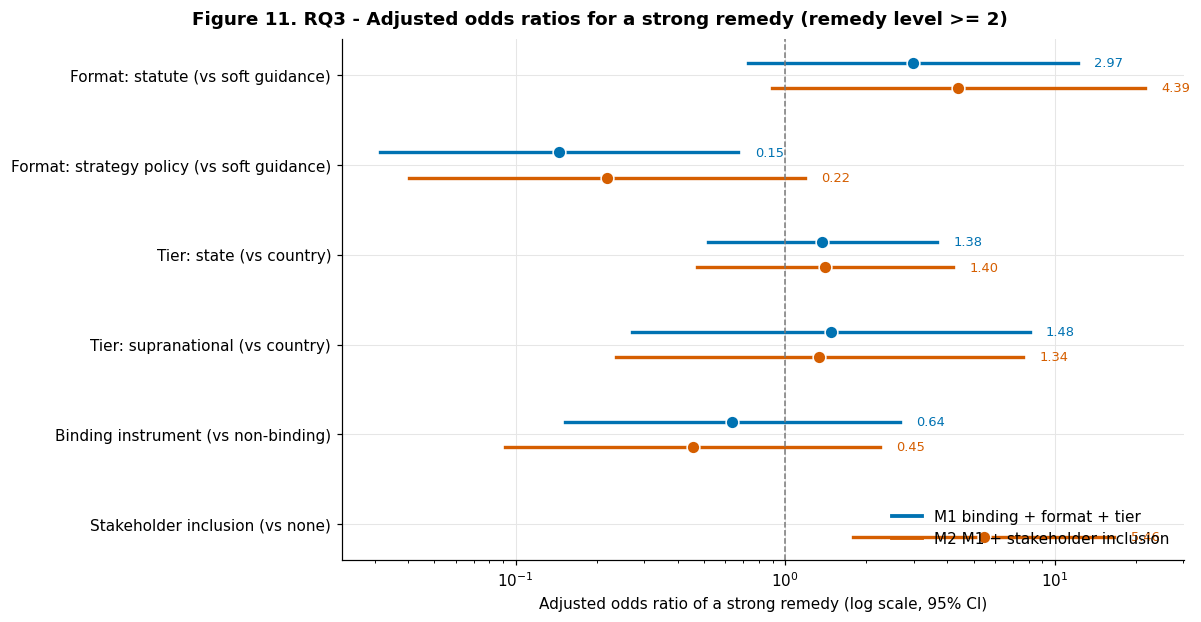

**Table 23. RQ3 - Predicted probability of a strong remedy from M1 (tier fixed at 'country'; 95% CI)**

,format3,legal_status,n,predicted_probability,ci_low,ci_high
0,soft_guidance,non-binding,31,0.132,0.048,0.312
1,soft_guidance,binding,4,0.088,0.020,0.319
2,statute,non-binding,5,0.311,0.112,0.617
3,statute,binding,71,0.223,0.115,0.389
4,strategy_policy,non-binding,127,0.022,0.007,0.067
5,strategy_policy,binding,6,0.014,0.002,0.083


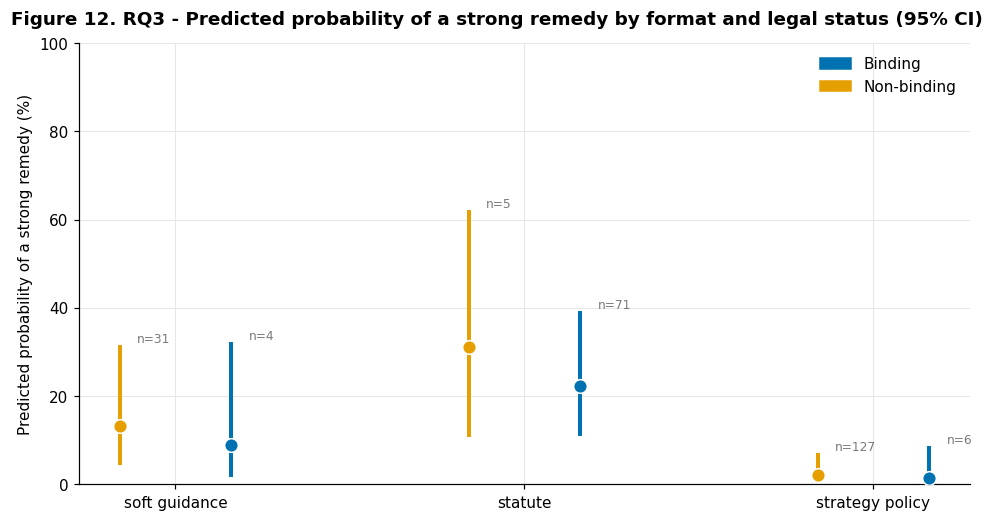

**Table 24. RQ3 - Exploratory ordered logit on the 0-3 remedy score (controls: format, tier)**

,coefficient,odds_ratio,OR_CI_low,OR_CI_high,p_value,N
term,,,,,,
Binding instrument (vs non-binding),-0.8171,0.4417,0.1343,1.4527,0.1786,244
Stakeholder inclusion (vs none),2.4480,11.5656,4.3627,30.6608,0.0000,244


In [9]:
def set_ref(series, ref):
    '''Categorical with `ref` as the reference (first) category.'''
    vals = sorted(pd.Series(series).dropna().astype(str).unique())
    ref = ref if ref in vals else vals[0]
    return pd.Categorical(pd.Series(series).astype(str), categories=[ref] + [v for v in vals if v != ref])

def prep(frame):
    '''Rebuild reference categories and the collapsed variables (tier2, format2) for a data subset.'''
    f = frame.dropna(subset=["format3", "tier"]).copy()
    f["format3"] = set_ref(f["format3"], "soft_guidance"); f["tier"] = set_ref(f["tier"], "country")
    f["tier2"] = set_ref(np.where(f["tier"].astype(str) == "country", "country", "non_country"), "country")
    f["format2"] = set_ref(np.where(f["format3"].astype(str) == "statute", "statute", "non_statute"), "non_statute")
    return f

def fit_logit(formula, data, outcome, min_events=MIN_EVENTS):
    n0, n1 = int((data[outcome] == 0).sum()), int((data[outcome] == 1).sum())
    if min(n0, n1) < min_events:
        return None, f"not estimated: {n1} events and {n0} non-events (minimum {min_events} each)"
    try:
        m = smf.logit(formula, data=data).fit(disp=False, cov_type="HC1", maxiter=200)
    except Exception as e:
        return None, f"not estimated: {type(e).__name__}"
    if not bool(m.mle_retvals.get("converged", False)):
        return None, "not estimated: optimiser did not converge"
    if (m.params.drop("Intercept", errors="ignore").abs() > 10).any():
        return None, "not estimated: separation (|coefficient| > 10)"
    return m, "estimated as specified"

def fit_with_collapse(formula, data, outcome):
    '''Fit; on separation/non-convergence collapse sparse categories (never drop them).'''
    variants = [(formula, "estimated as specified"),
                (formula.replace("C(tier)", "C(tier2)"), "tier collapsed (country vs other)"),
                (formula.replace("C(tier)", "C(tier2)").replace("C(format3)", "C(format2)"), "tier and format collapsed")]
    status = ""
    for f, note in variants:
        if f != formula and f == variants[0][0]:
            continue
        m, status = fit_logit(f, data, outcome)
        if m is not None:
            return m, note, f
        if status.startswith("not estimated: ") and "minimum" in status:
            break
    return None, status, formula

def pretty(term):
    m = re.match(r"C\((\w+)\)\[T\.(.+)\]$", term)
    if m:
        var, lev = m.groups(); ref = {"format3": "soft guidance", "tier": "country", "tier2": "country", "format2": "non-statute"}.get(var, "reference")
        return f"{ {'format3': 'Format', 'tier': 'Tier', 'tier2': 'Tier', 'format2': 'Format'}[var] }: {lev.replace('_', ' ')} (vs {ref})"
    return {"binding": "Binding instrument (vs non-binding)", "inclusion": "Stakeholder inclusion (vs none)", "Intercept": "Intercept"}.get(term, term)

d = prep(pol)
d_bind = prep(pol[pol["is_binding"]])
print("Complete-case N for regression:", len(d), "| binding-only N:", len(d_bind))

# Design diagnostics: expose sparse format x legal-status cells before interpreting
# adjusted coefficients. Strong overlap means the independent effects are weakly identified.
format_law_cells = pd.crosstab(d["format3"].astype(str), d["binding"].map({0:"non-binding", 1:"binding"}))
show(format_law_cells, "RQ3 diagnostic: format by legal status (inspect sparse/empty cells)",
     "t21b_rq3_format_by_legal_status")
print("Interpretation warning: these are observational associations, not causal effects. "
      "Where format and legal status nearly determine one another, adjusted coefficients "
      "are unstable and should be treated as exploratory rather than independent effects.")

SPECS = [
    ("M1: strong remedy ~ binding + format + tier (proposal specification)", "procedural_or_enforceable ~ binding + C(format3) + C(tier)", "procedural_or_enforceable", d),
    ("M2: M1 + stakeholder inclusion", "procedural_or_enforceable ~ binding + inclusion + C(format3) + C(tier)", "procedural_or_enforceable", d),
    ("M3: strong remedy ~ inclusion + format + tier", "procedural_or_enforceable ~ inclusion + C(format3) + C(tier)", "procedural_or_enforceable", d),
    ("M4: explicit right/remedy ~ inclusion + format + tier", "enforceable_remedy ~ inclusion + C(format3) + C(tier)", "enforceable_remedy", d),
    ("M5: binding instruments only", "procedural_or_enforceable ~ inclusion + C(format3) + C(tier)", "procedural_or_enforceable", d_bind)]

MODELS, overview, coefs = {}, [], []
for label, formula, outcome, data in SPECS:
    model, note, used = fit_with_collapse(formula, data, outcome)
    MODELS[label] = (model, used, data)
    row = {"model": label, "outcome": outcome, "N": len(data), "events": int(data[outcome].sum()), "status": note}
    if model is not None:
        row.update({"pseudo_R2": round(model.prsquared, 3), "LR_test_p": model.llr_pvalue, "AIC": round(model.aic, 1)})
        ci = model.conf_int()
        coefs.append(pd.DataFrame({"model": label, "term": [pretty(t) for t in model.params.index], "odds_ratio": np.exp(model.params.values),
                                  "OR_CI_low": np.exp(ci.iloc[:, 0].values), "OR_CI_high": np.exp(ci.iloc[:, 1].values),
                                  "p_value": model.pvalues.values}))
    overview.append(row)
overview = pd.DataFrame(overview).set_index("model")
show(overview, "Table 21. RQ3 - Exploratory model overview (estimation status, events, pseudo-R2, likelihood-ratio test)", "t21_rq3_model_overview")
for lbl, r in overview.iterrows():
    if not str(r["status"]).startswith("estimated") and "collapsed" not in str(r["status"]):
        print(f"- {lbl.split(':')[0]}: {r['status']}")

if coefs:
    coef_tbl = pd.concat(coefs, ignore_index=True)
    show(coef_tbl.round(4), "Table 22. RQ3 - Exploratory adjusted odds ratios (95% CI, HC1 robust SE); interpret cautiously", "t22_rq3_model_coefficients", index=False)
else:
    coef_tbl = pd.DataFrame()
    print("No logit model met the pre-specified estimation checks; use the descriptive tables (Tables 14-20).")

# ---- Figure 11: forest plot (M1 and M2)
fo = coef_tbl[coef_tbl["model"].str.startswith(("M1", "M2")) & (coef_tbl["term"] != "Intercept")] if len(coef_tbl) else pd.DataFrame()
if len(fo):
    terms = list(dict.fromkeys(fo["term"])); yy = np.arange(len(terms))[::-1]
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(terms) + 2.2))
    for j, (mname, c) in enumerate([("M1", PAL["blue"]), ("M2", PAL["red"])]):
        sub = fo[fo["model"].str.startswith(mname)]
        for _, r in sub.iterrows():
            yi = yy[terms.index(r["term"])] + (0.14 if j == 0 else -0.14)
            ax.plot([r["OR_CI_low"], r["OR_CI_high"]], [yi, yi], color=c, lw=2.2)
            ax.scatter(r["odds_ratio"], yi, s=70, color=c, edgecolor="white", zorder=3)
            ax.text(max(r["OR_CI_high"], r["odds_ratio"]) * 1.15, yi, f"{r['odds_ratio']:.2f}", va="center", fontsize=8.5, color=c)
    ax.axvline(1, color=PAL["grey"], ls="--", lw=1); ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels(terms)
    ax.set_xlabel("Adjusted odds ratio of a strong remedy (log scale, 95% CI)")
    ax.legend(handles=[Line2D([0], [0], color=PAL["blue"], lw=2.5, label="M1 binding + format + tier"), Line2D([0], [0], color=PAL["red"], lw=2.5, label="M2 M1 + stakeholder inclusion")], loc="lower right")
    plt.tight_layout(); savefig("fig11_rq3_odds_ratio_forest", "Figure 11. RQ3 - Adjusted odds ratios for a strong remedy (remedy level >= 2)")

# ---- predicted probabilities from M1 (delta method with the HC1 covariance matrix)
def predict_prob(model, scen):
    names = list(model.params.index); X = np.zeros((len(scen), len(names)))
    for j, nm in enumerate(names):
        mt = re.match(r"C\((\w+)\)\[T\.(.+)\]$", nm)
        if nm == "Intercept": X[:, j] = 1.0
        elif mt: X[:, j] = (scen[mt.group(1)].astype(str) == mt.group(2)).astype(float).values
        else: X[:, j] = scen[nm].astype(float).values
    xb = X @ model.params.values; cov = np.asarray(model.cov_params()); se = np.sqrt(np.einsum("ij,jk,ik->i", X, cov, X))
    inv = lambda z: 1 / (1 + np.exp(-z))
    return inv(xb), inv(xb - 1.96 * se), inv(xb + 1.96 * se)

m1_label = SPECS[0][0]; m1, m1_formula, m1_data = MODELS[m1_label]
if m1 is not None:
    modal_tier = d["tier"].astype(str).value_counts().index[0]
    combos = d.groupby(["format3", "binding"], observed=True).size().reset_index(name="n").query("n > 0")
    scen = combos.copy(); scen["format3"] = scen["format3"].astype(str); scen["tier"] = modal_tier
    scen["tier2"] = "country" if modal_tier == "country" else "non_country"; scen["format2"] = np.where(scen["format3"] == "statute", "statute", "non_statute")
    p, lo, hi = predict_prob(m1, scen)
    pp = scen[["format3", "binding", "n"]].assign(predicted_probability=p.round(3), ci_low=lo.round(3), ci_high=hi.round(3))
    pp["legal_status"] = np.where(pp["binding"] == 1, "binding", "non-binding")
    show(pp[["format3", "legal_status", "n", "predicted_probability", "ci_low", "ci_high"]],
         f"Table 23. RQ3 - Predicted probability of a strong remedy from M1 (tier fixed at '{modal_tier}'; 95% CI)", "t23_rq3_predicted_probabilities", index=False)
    fig, ax = plt.subplots(figsize=(9, 4.6)); fm = list(pp["format3"].unique())
    for _, r in pp.iterrows():
        x = fm.index(r["format3"]) + (0.16 if r["binding"] == 1 else -0.16); c = LAW_COL[b1 if r["binding"] == 1 else b2]
        ax.plot([x, x], [100 * r["ci_low"], 100 * r["ci_high"]], color=c, lw=2.6)
        ax.scatter(x, 100 * r["predicted_probability"], s=80, color=c, edgecolor="white", zorder=3)
        ax.text(x + 0.05, 100 * r["ci_high"] + 1, f"n={int(r['n'])}", fontsize=8, color=PAL["grey"])
    ax.set_xticks(range(len(fm))); ax.set_xticklabels([f.replace("_", " ") for f in fm]); ax.set_ylabel("Predicted probability of a strong remedy (%)")
    ax.set_ylim(0, 100); ax.legend(handles=[Patch(color=LAW_COL[b1], label="Binding"), Patch(color=LAW_COL[b2], label="Non-binding")])
    plt.tight_layout(); savefig("fig12_rq3_predicted_probabilities", "Figure 12. RQ3 - Predicted probability of a strong remedy by format and legal status (95% CI)")
else:
    print("M1 was not estimated, so no predicted probabilities are reported.")

# ---- ordered logit on the 0-3 remedy score (robustness)
try:
    from statsmodels.miscmodels.ordinal_model import OrderedModel
    od = d[["remedy", "binding", "inclusion", "format3", "tier"]].dropna().copy(); od["remedy"] = od["remedy"].astype(int)
    if od["remedy"].nunique() >= 3:
        X = pd.get_dummies(od[["binding", "inclusion", "format3", "tier"]], drop_first=True, dtype=float)
        om = OrderedModel(od["remedy"], X, distr="logit").fit(method="bfgs", disp=False)
        ci = om.conf_int(); rows = []
        for term in ["binding", "inclusion"]:
            if term in om.params.index:
                rows.append({"term": pretty(term), "coefficient": om.params[term], "odds_ratio": np.exp(om.params[term]),
                             "OR_CI_low": np.exp(ci.loc[term].iloc[0]), "OR_CI_high": np.exp(ci.loc[term].iloc[1]), "p_value": om.pvalues[term], "N": len(od)})
        if rows:
            show(pd.DataFrame(rows).set_index("term").round(4), "Table 24. RQ3 - Exploratory ordered logit on the 0-3 remedy score (controls: format, tier)", "t24_rq3_ordered_logit")
    else:
        print("Ordered logit skipped: fewer than three remedy levels are represented.")
except Exception as err:
    print("Ordered-logit robustness model skipped:", repr(err))

### 7c. Binding instruments only: does stakeholder recognition go with a strong remedy? (replaces model M5)
**What this cell does.** The binding-only logit (M5) cannot be estimated reliably (19 strong-remedy documents among 81 binding ones, and sparse format/tier cells). This cell answers the same RQ3 question **without a model**: among the 81 binding instruments, it compares the share with a strong remedy (remedy level ≥ 2) between documents that recognise at least one stakeholder group and those that do not, using Fisher's exact test and an odds ratio (Haldane–Anscombe correction if a cell is zero). The same comparison is repeated for the accountability index (Mann–Whitney) and for the five accountability features.

**Research question.** RQ3, restricted to binding (hard-law) instruments, so that the binding/non-binding difference cannot explain the result.

**How to read it.** A large odds ratio with a confidence interval above 1 means that, even among binding instruments, those that name a stakeholder group are more likely to contain a procedural or explicit remedy. Counts are small, so intervals are wide.

**Output.** `t27_rq3_binding_only_inclusion.csv`.

In [10]:
bd = pol[pol["is_binding"]].copy()
rows = []
for flag, lab in [("procedural_or_enforceable", "Strong remedy (remedy level >= 2)"), ("f_oversight_enforcement", "Oversight and enforcement"),
                  ("f_duty_holder", "Duty-holder identified"), ("f_implementation_support", "Implementation support")]:
    r = compare_binary(bd, flag, "inclusion", 1, 0)
    rows.append({"indicator": lab, "n_recognising": r["n_g1"], "with_indicator_recognising": r["events_g1"], "pct_recognising": r["pct_g1"],
                 "n_not_recognising": r["n_g2"], "with_indicator_not_recognising": r["events_g2"], "pct_not_recognising": r["pct_g2"],
                 "odds_ratio": r["odds_ratio"], "OR_CI_low": r["OR_CI_low"], "OR_CI_high": r["OR_CI_high"], "fisher_p": r["fisher_p"]})
bd_tbl = pd.DataFrame(rows)
mw = stats.mannwhitneyu(bd.loc[bd["inclusion"] == 1, "accountability_index"], bd.loc[bd["inclusion"] == 0, "accountability_index"])[1]
show(bd_tbl.round(4), f"Table 27. RQ3 - Binding instruments only (n = {len(bd)}): indicators by stakeholder recognition (Fisher's exact test)", "t27_rq3_binding_only_inclusion", index=False)
print(f"Mean accountability index among binding instruments: recognising = {bd.loc[bd['inclusion'] == 1, 'accountability_index'].mean():.2f} "
      f"(n={int((bd['inclusion'] == 1).sum())}), not recognising = {bd.loc[bd['inclusion'] == 0, 'accountability_index'].mean():.2f} (n={int((bd['inclusion'] == 0).sum())}); Mann-Whitney p = {mw:.4f}")

**Table 27. RQ3 - Binding instruments only (n = 81): indicators by stakeholder recognition (Fisher's exact test)**

,indicator,n_recognising,with_indicator_recognising,pct_recognising,n_not_recognising,with_indicator_not_recognising,pct_not_recognising,odds_ratio,OR_CI_low,OR_CI_high,fisher_p
0,Strong remedy (remedy level >= 2),14,8,57.1,67,11,16.4,6.79,1.96,23.46,0.0029
1,Oversight and enforcement,14,7,50.0,67,23,34.3,1.91,0.60,6.12,0.3628
2,Duty-holder identified,14,5,35.7,67,23,34.3,1.06,0.32,3.54,1.0000
3,Implementation support,14,7,50.0,67,9,13.4,6.44,1.83,22.75,0.0050


Mean accountability index among binding instruments: recognising = 2.50 (n=14), not recognising = 0.99 (n=67); Mann-Whitney p = 0.0008


## 8. RQ4: How do stakeholder protection and enforceable accountability differ across jurisdictions and policy implementation stages?
### 8a. Which actors do obligations address?
**What this cell does.** Searches every recorded obligation for references to five **actor types** (provider/developer, deployer/user organisation, importer/distributor, public authority, general-purpose/frontier model provider) using the actor lexicon from section 3, and reports how many obligations name each actor (overall and binding only), plus the **share of each actor's obligations that fall in operational/technical categories** (documentation, testing, record keeping, conformity assessment, monitoring and so on). It also builds the actor × obligation-category count matrix.

**Figures.** *Figure 13* (a) obligations per actor (all and binding), (b) operational/technical share per actor. *Figure 14* heat map of obligation category by actor reference.

**How to read it.** Actor categories overlap (one obligation can name several actors), so totals can exceed the number of obligations. Keyword matches show who is *named*, not who is legally responsible.

**Outputs.** `t25` and `t26` CSVs, `fig13`, `fig14`.

**Table 25. RQ4 - Obligations naming each actor type (overlapping categories) and operational/technical share**

,n_obligations_naming_actor,n_binding_obligations,pct_of_all_obligations,n_operational_technical,pct_operational_technical
Provider / developer,51,49,43.6,20,39.2
Deployer / user organisation,59,52,50.4,13,22.0
Importer / distributor,8,8,6.8,2,25.0
Public authority,39,34,33.3,11,28.2
General-purpose / frontier model,10,10,8.5,5,50.0


Obligations: 117 | actor references in total: 167 | obligations with no actor detected: 21


**Table 26. RQ4 - Obligation category by actor reference (counts)**

,Provider / developer,Deployer / user organisation,Importer / distributor,Public authority,General-purpose / frontier model
category,,,,,
transparency,7,19,0,5,1
governance_accountability,9,8,3,10,2
incident_handling,5,4,1,3,1
risk_management,4,4,0,2,0
technical_documentation,4,2,0,2,1
prohibited_practice,3,2,1,2,0
human_oversight,0,4,0,4,0
safety_testing,3,1,0,1,2
public_sector_use,2,1,1,2,0


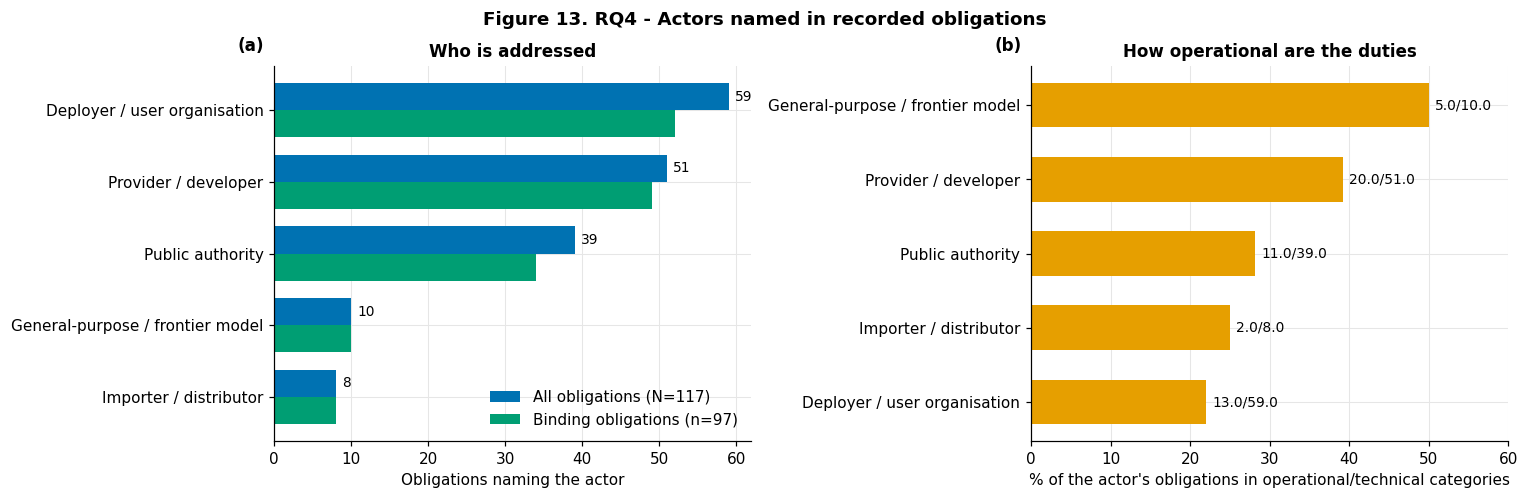

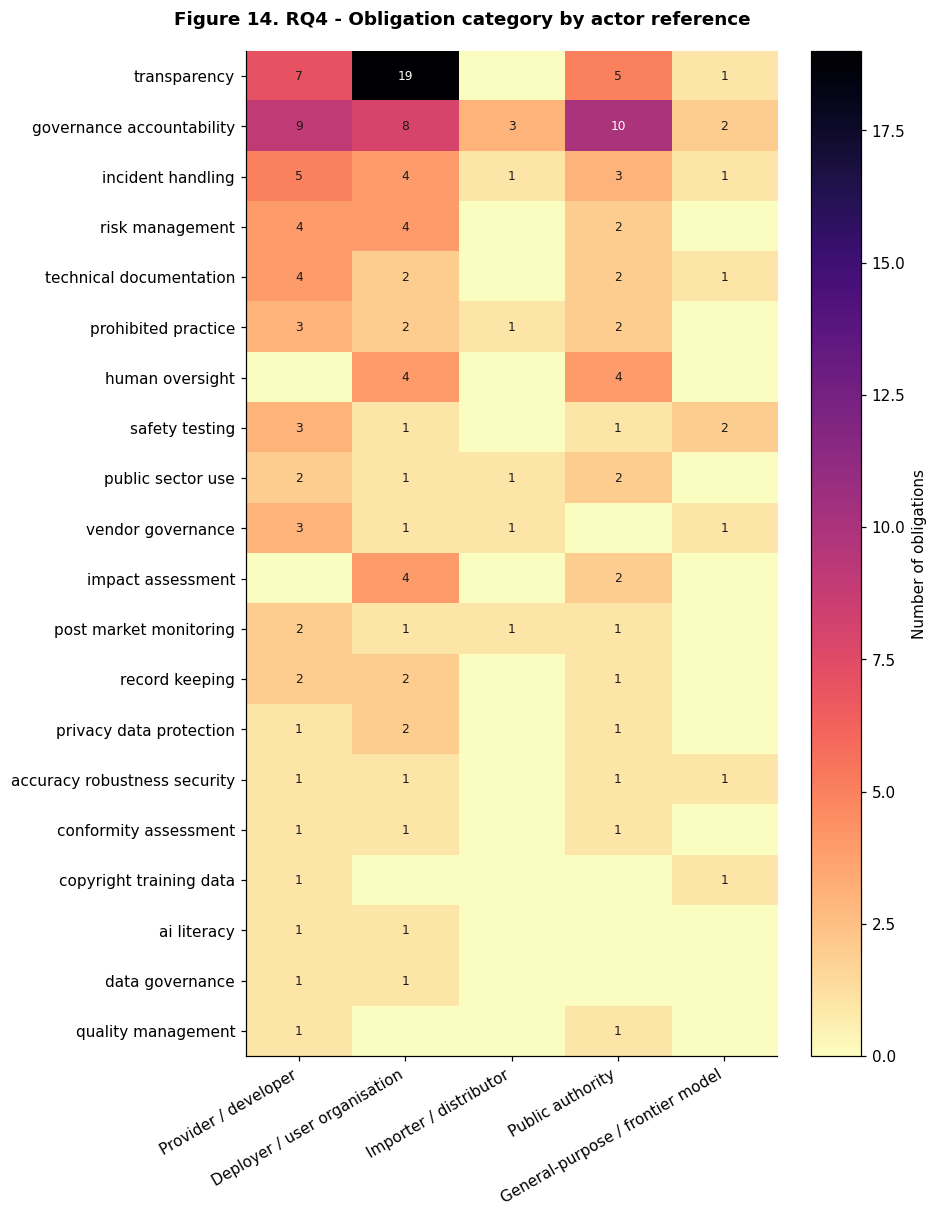

In [11]:
for actor, pat in ACTORS.items():
    obl[f"actor_ref_{actor}"] = obl["obl_text"].fillna("").astype(str).str.contains(pat, flags=re.I, regex=True)
actor_cols = [f"actor_ref_{a}" for a in ACTORS]
OPERATIONAL = ["technical_documentation", "safety_testing", "record_keeping", "accuracy_robustness_security", "conformity_assessment",
               "post_market_monitoring", "quality_management", "data_governance", "incident_handling"]
obl["operational_technical"] = obl["category"].isin(OPERATIONAL)
ACTOR_LABEL = {"provider_developer": "Provider / developer", "deployer_user_organisation": "Deployer / user organisation",
               "importer_distributor": "Importer / distributor", "public_authority": "Public authority", "gpai_frontier": "General-purpose / frontier model"}

act = pd.DataFrame({
    "n_obligations_naming_actor": obl[actor_cols].sum().values,
    "n_binding_obligations": obl.loc[obl["is_binding"], actor_cols].sum().values,
    "pct_of_all_obligations": (100 * obl[actor_cols].mean()).round(1).values,
    "n_operational_technical": [int(obl.loc[obl[c], "operational_technical"].sum()) for c in actor_cols],
    "pct_operational_technical": [round(100 * obl.loc[obl[c], "operational_technical"].mean(), 1) if obl[c].sum() else np.nan for c in actor_cols]},
    index=[ACTOR_LABEL[a] for a in ACTORS])
show(act, "Table 25. RQ4 - Obligations naming each actor type (overlapping categories) and operational/technical share", "t25_rq4_actor_references")
print("Obligations:", len(obl), "| actor references in total:", int(obl[actor_cols].to_numpy().sum()),
      "| obligations with no actor detected:", int((obl[actor_cols].sum(axis=1) == 0).sum()))

heat_a = pd.DataFrame({ACTOR_LABEL[a]: obl.loc[obl[c]].groupby("category").size() for a, c in zip(ACTORS, actor_cols)}).fillna(0).astype(int)
heat_a = heat_a.loc[heat_a.sum(axis=1).sort_values(ascending=False).index]
show(heat_a, "Table 26. RQ4 - Obligation category by actor reference (counts)", "t26_rq4_actor_by_category")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
a_sorted = act.sort_values("n_obligations_naming_actor"); yy = np.arange(len(a_sorted)); h = 0.38
ax1.barh(yy + h / 2, a_sorted["n_obligations_naming_actor"], height=h, color=PAL["blue"], label=f"All obligations (N={len(obl)})")
ax1.barh(yy - h / 2, a_sorted["n_binding_obligations"], height=h, color=PAL["green"], label=f"Binding obligations (n={int(obl['is_binding'].sum())})")
for yi, v in zip(yy, a_sorted["n_obligations_naming_actor"]): ax1.text(v + 0.8, yi + h / 2, int(v), va="center", fontsize=9)
ax1.set_yticks(yy); ax1.set_yticklabels(a_sorted.index); ax1.set_xlabel("Obligations naming the actor"); ax1.legend(loc="lower right"); ax1.set_title("Who is addressed"); panel(ax1, "a")
o_sorted = act.sort_values("pct_operational_technical", na_position="first"); yy = np.arange(len(o_sorted))
ax2.barh(yy, o_sorted["pct_operational_technical"].fillna(0), color=PAL["orange"], height=0.6)
for yi, (_, r) in zip(yy, o_sorted.iterrows()): ax2.text(r["pct_operational_technical"] + 0.8 if pd.notna(r["pct_operational_technical"]) else 0.8, yi, f"{r['n_operational_technical']}/{r['n_obligations_naming_actor']}", va="center", fontsize=9)
ax2.set_yticks(yy); ax2.set_yticklabels(o_sorted.index); ax2.set_xlabel("% of the actor's obligations in operational/technical categories"); ax2.set_xlim(0, 60); ax2.set_title("How operational are the duties"); panel(ax2, "b")
plt.tight_layout(); savefig("fig13_rq4_actor_references", "Figure 13. RQ4 - Actors named in recorded obligations")

fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(heat_a) + 2.4))
im = ax.imshow(heat_a.values, cmap="magma_r", aspect="auto"); ax.grid(False)
ax.set_xticks(range(heat_a.shape[1])); ax.set_xticklabels(heat_a.columns, rotation=30, ha="right"); ax.set_yticks(range(len(heat_a))); ax.set_yticklabels([c.replace("_", " ") for c in heat_a.index])
for i in range(heat_a.shape[0]):
    for k in range(heat_a.shape[1]):
        v = heat_a.iat[i, k]
        if v: ax.text(k, i, v, ha="center", va="center", fontsize=8, color="white" if v > 0.5 * heat_a.values.max() else PAL["ink"])
plt.colorbar(im, ax=ax, label="Number of obligations"); plt.tight_layout()
savefig("fig14_rq4_actor_by_category_heatmap", "Figure 14. RQ4 - Obligation category by actor reference")

### 8b. Jurisdictions: concentration and jurisdiction-level indices
**What this cell does.**
* **Concentration:** the number and share of recorded obligations per jurisdiction, the **Herfindahl–Hirschman index (HHI)** (sum of squared shares; 1/*k* for *k* equally sized jurisdictions, 1 for a single jurisdiction) and the cumulative share of the largest jurisdictions.
* **Jurisdiction-level indices (proposal Table 4.4 and Figure 4.2):** for every jurisdiction with at least `MIN_DOCS` policies, the number of policies and obligations, the share of binding instruments, the **recognition index** (mean number of stakeholder groups recognised per policy), the share of policies recognising any group, the share with a strong remedy and the mean **accountability index**.
* **Tier comparison:** the same indices by jurisdictional tier (country, state, supranational).

**Figures.** *Figure 15* (a) obligations by jurisdiction with the cumulative share, (b) a bubble chart of recognition index versus accountability index (bubble size = obligations, colour = share of binding instruments), which shows jurisdictions that name more groups *and* those that attach more accountability features.

**How to read it.** Indices rest on few documents per jurisdiction (the counts are shown); treat them as descriptive profiles, not rankings.

**Outputs.** `t28_rq4_obligations_by_jurisdiction.csv`, `t29_rq4_jurisdiction_comparison.csv`, `t30_rq4_tier_comparison.csv`, `fig15`.

**Table 28. RQ4 - Recorded obligations by jurisdiction (top share = 0.376; HHI = 0.184; 13 jurisdictions; equal-share HHI would be 0.077)**

,n_obligations,share_%,cumulative_share_%
jurisdiction,,,
eu,44,37.6,37.6
us-colorado,15,12.8,50.4
south-korea,9,7.7,58.1
uk,7,6.0,64.1
us,7,6.0,70.1
us-texas,7,6.0,76.1
singapore,6,5.1,81.2
us-new-york,5,4.3,85.5
us-california,5,4.3,89.7


**Table 29. RQ4 - Jurisdiction comparison summary (jurisdictions with >= 3 policies; n = 19)**

,n_policies,n_obligations,pct_binding,recognition_index_mean_groups,pct_recognising_any_group,pct_strong_remedy,accountability_index_mean
jurisdiction,,,,,,,
us-california,7,5,100.0,0.14,14.3,14.3,1.57
singapore,7,6,0.0,0.29,28.6,0.0,0.57
international,6,0,0.0,0.17,16.7,16.7,1.17
us,5,7,60.0,0.20,20.0,20.0,1.20
uae,4,3,25.0,0.00,0.0,25.0,1.00
uk,4,7,0.0,0.50,50.0,50.0,2.75
india,4,4,25.0,0.25,25.0,25.0,1.25
us-illinois,4,0,100.0,0.25,25.0,50.0,1.50
canada,3,0,0.0,0.00,0.0,0.0,1.00


**Table 30. RQ4 - Indices by jurisdictional tier**

,n_policies,n_obligations,pct_binding,recognition_index_mean_groups,pct_recognising_any_group,pct_strong_remedy,accountability_index_mean
tier,,,,,,,
country,164,41,17.7,0.08,6.7,7.9,0.64
state,67,32,74.6,0.13,13.4,19.4,0.93
supranational,13,44,15.4,0.23,15.4,15.4,1.08


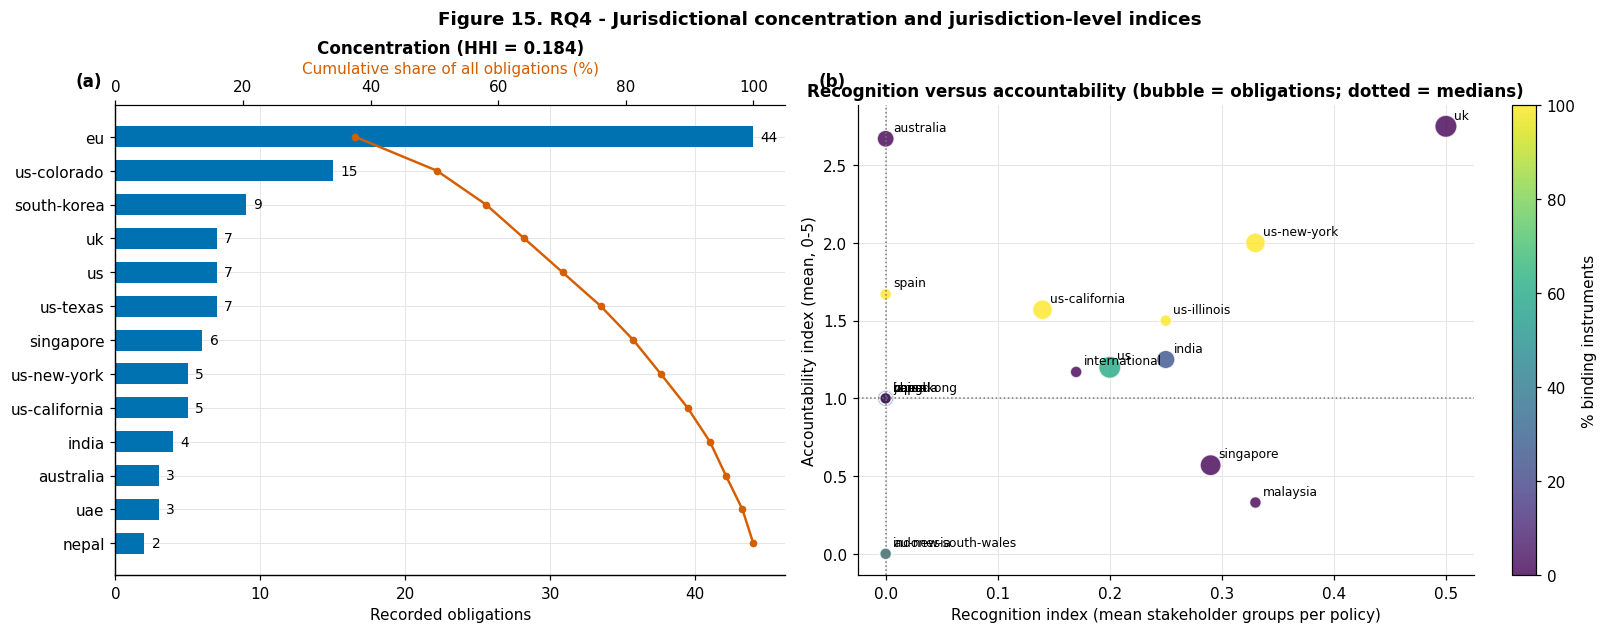

In [12]:
jc = obl["jurisdiction"].fillna("Unknown").value_counts()
js = jc / jc.sum()
hhi = float((js ** 2).sum())
jtab = pd.DataFrame({"n_obligations": jc, "share_%": (100 * js).round(1), "cumulative_share_%": (100 * js.cumsum()).round(1)})
show(jtab, f"Table 28. RQ4 - Recorded obligations by jurisdiction (top share = {js.iloc[0]:.3f}; HHI = {hhi:.3f}; {len(jc)} jurisdictions; equal-share HHI would be {1 / len(jc):.3f})",
     "t28_rq4_obligations_by_jurisdiction")

# ---- jurisdiction-level indices
def jur_profile(grouped):
    return pd.DataFrame({
        "n_policies": grouped.size(),
        "pct_binding": (100 * grouped["binding"].mean()).round(1),
        "recognition_index_mean_groups": grouped["n_groups"].mean().round(2),
        "pct_recognising_any_group": (100 * grouped["inclusion"].mean()).round(1),
        "pct_strong_remedy": (100 * grouped["procedural_or_enforceable"].mean()).round(1),
        "accountability_index_mean": grouped["accountability_index"].mean().round(2)})
jp = jur_profile(pol.groupby("jurisdiction"))
jp.insert(1, "n_obligations", obl["jurisdiction"].value_counts().reindex(jp.index).fillna(0).astype(int))
jp_main = jp[jp["n_policies"] >= MIN_DOCS].sort_values("n_policies", ascending=False)
show(jp_main, f"Table 29. RQ4 - Jurisdiction comparison summary (jurisdictions with >= {MIN_DOCS} policies; n = {len(jp_main)})", "t29_rq4_jurisdiction_comparison")
tier_tbl = jur_profile(pol.groupby("tier"))
tier_tbl.insert(1, "n_obligations", [int(obl.loc[obl["policy"].isin(pol.loc[pol["tier"] == t, "slug"])].shape[0]) for t in tier_tbl.index])
show(tier_tbl, "Table 30. RQ4 - Indices by jurisdictional tier", "t30_rq4_tier_comparison")

# ---- Figure 15
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.15]})
top = jtab.head(15).iloc[::-1]; yy = np.arange(len(top))
ax1.barh(yy, top["n_obligations"], color=PAL["blue"], height=0.62)
for yi, v in zip(yy, top["n_obligations"]): ax1.text(v + 0.5, yi, int(v), va="center", fontsize=9)
ax1.set_yticks(yy); ax1.set_yticklabels(top.index); ax1.set_xlabel("Recorded obligations"); ax1.set_title(f"Concentration (HHI = {hhi:.3f})", pad=34)
axc = ax1.twiny(); axc.plot(top["cumulative_share_%"], yy, color=PAL["red"], marker="o", ms=4, lw=1.6); axc.set_xlim(0, 105); axc.grid(False)
axc.set_xlabel("Cumulative share of all obligations (%)", color=PAL["red"]); axc.spines["top"].set_visible(True); panel(ax1, "a")
if len(jp_main):
    sz = 60 + 22 * jp_main["n_obligations"]
    sc = ax2.scatter(jp_main["recognition_index_mean_groups"], jp_main["accountability_index_mean"], s=sz, c=jp_main["pct_binding"], cmap="viridis",
                     alpha=0.8, edgecolor="white", vmin=0, vmax=100)
    for name, r in jp_main.iterrows():
        ax2.annotate(name, (r["recognition_index_mean_groups"], r["accountability_index_mean"]), xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax2.axvline(jp_main["recognition_index_mean_groups"].median(), color=PAL["grey"], ls=":", lw=1); ax2.axhline(jp_main["accountability_index_mean"].median(), color=PAL["grey"], ls=":", lw=1)
    plt.colorbar(sc, ax=ax2, label="% binding instruments")
    ax2.set_xlabel("Recognition index (mean stakeholder groups per policy)"); ax2.set_ylabel("Accountability index (mean, 0-5)")
    ax2.set_title("Recognition versus accountability (bubble = obligations; dotted = medians)"); panel(ax2, "b")
plt.tight_layout(); savefig("fig15_rq4_jurisdictions", "Figure 15. RQ4 - Jurisdictional concentration and jurisdiction-level indices")

### 8c. Implementation stages: published versus unverified records
**What this cell does.** The implementation file has only a few records (typically eight), so they are reported **descriptively** with case examples (proposal 6.5): the full record list, a cross-tabulation of record kind by verification status, and the share of records that are *published* (evidence of delivery) versus *unverified*. If the implementation table contains a column linking records to policies, the notebook also counts how many policies have a linked implementation record (the framework's stage 4); if no such column exists this step is skipped and a message says so.

**Figure.** *Figure 16* (a) records by kind and status, (b) the confidence level attached to each record.

**How to read it.** With so few records no inferential test is meaningful. An *unverified* record means the tracker could not confirm publication, so it is weaker evidence of delivery; it is not proof that the measure does not exist.

**Outputs.** `t31_rq4_implementation_records.csv`, `t32_rq4_implementation_kind_status.csv`, `fig16`.

**Table 31. RQ4 - Implementation records (descriptive; n = 8)**

,slug,kind,status,source_tier,published_on,confidence_level
0,eu-ai-act-ai-generated-content-marking-code,code_of_practice,unverified,4,NaT,unavailable
1,eu-ai-act-gpai-code-of-practice,code_of_practice,published,2,2025-07-10,medium
2,eu-ai-act-guidelines-on-prohibited-practices,guidelines,published,2,2025-02-04,medium
3,eu-ai-act-high-risk-classification-guidelines,guidelines,unverified,4,NaT,unavailable
4,eu-ai-act-training-content-summary-template,template,unverified,4,NaT,unavailable
5,iso-iec-42001-2023,iso_work_item,published,1,2023-12-18,medium
6,iso-iec-42005-2025,iso_work_item,published,1,2025-01-01,medium
7,iso-iec-42006-2025,iso_work_item,published,1,2025-01-01,medium


Case examples:
 - slug: eu-ai-act-ai-generated-content-marking-code | kind: code_of_practice | status: unverified | source_tier: 4 | published_on: NaT | confidence_level: unavailable
 - slug: eu-ai-act-gpai-code-of-practice | kind: code_of_practice | status: published | source_tier: 2 | published_on: 2025-07-10 00:00:00 | confidence_level: medium
 - slug: eu-ai-act-guidelines-on-prohibited-practices | kind: guidelines | status: published | source_tier: 2 | published_on: 2025-02-04 00:00:00 | confidence_level: medium
 - slug: eu-ai-act-high-risk-classification-guidelines | kind: guidelines | status: unverified | source_tier: 4 | published_on: NaT | confidence_level: unavailable
 - slug: eu-ai-act-training-content-summary-template | kind: template | status: unverified | source_tier: 4 | published_on: NaT | confidence_level: unavailable
 - slug: iso-iec-42001-2023 | kind: iso_work_item | status: published | source_tier: 1 | published_on: 2023-12-18 00:00:00 | confidence_level: medium
 - s

**Table 32. RQ4 - Implementation records by kind and verification status**

status,published,unverified,total
kind,,,
code_of_practice,1,1,2
guidelines,1,1,2
iso_work_item,3,0,3
template,0,1,1


Status shares (%): {'published': 62.5, 'unverified': 37.5}


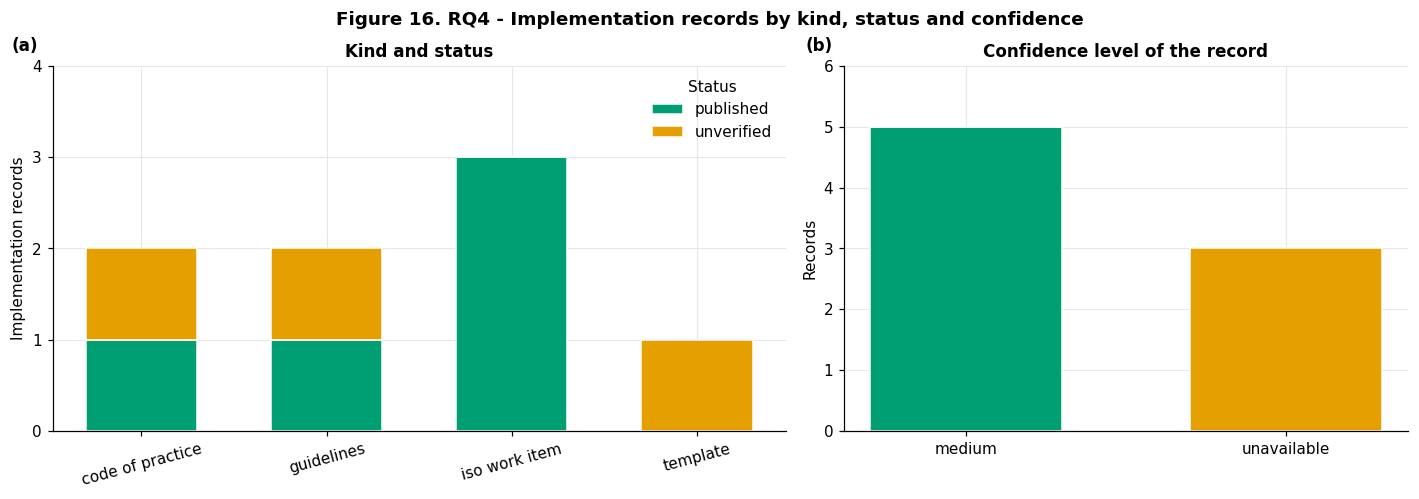

Implementation records linked to a policy via 'related_policy': 2 of 8


In [13]:
cols = [c for c in ["slug", "kind", "status", "source_tier", "published_on", "confidence_level"] if c in imp.columns]
show(imp[cols], f"Table 31. RQ4 - Implementation records (descriptive; n = {len(imp)})", "t31_rq4_implementation_records", index=False)

print("Case examples:")
for _, r in imp[cols].iterrows():
    print(" -", " | ".join(f"{c}: {r[c]}" for c in cols))

if {"kind", "status"}.issubset(imp.columns):
    ks = imp.groupby(["kind", "status"], dropna=False).size().unstack(fill_value=0)
    ks["total"] = ks.sum(axis=1)
    show(ks, "Table 32. RQ4 - Implementation records by kind and verification status", "t32_rq4_implementation_kind_status")
    status_share = imp["status"].value_counts(normalize=True).mul(100).round(1)
    print("Status shares (%):", status_share.to_dict())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
    STATUS_COL = {"published": PAL["green"], "unverified": PAL["orange"]}
    stat_cols = [c for c in ks.columns if c != "total"]
    bottom = np.zeros(len(ks))
    for s in stat_cols:
        ax1.bar(range(len(ks)), ks[s].values, bottom=bottom, label=s, color=STATUS_COL.get(s, PAL["pink"]), edgecolor="white", width=0.6); bottom += ks[s].values
    ax1.set_xticks(range(len(ks))); ax1.set_xticklabels([k.replace("_", " ") for k in ks.index], rotation=15); ax1.set_ylabel("Implementation records")
    ax1.set_yticks(range(0, int(bottom.max()) + 2)); ax1.legend(title="Status"); ax1.set_title("Kind and status"); panel(ax1, "a")
    if "confidence_level" in imp.columns:
        cl = imp.assign(confidence=imp["confidence_level"].fillna("unavailable")).groupby(["confidence", "status"]).size().unstack(fill_value=0)
        bottom = np.zeros(len(cl))
        for s in cl.columns:
            ax2.bar(range(len(cl)), cl[s].values, bottom=bottom, label=s, color=STATUS_COL.get(s, PAL["pink"]), edgecolor="white", width=0.6); bottom += cl[s].values
        ax2.set_xticks(range(len(cl))); ax2.set_xticklabels(cl.index); ax2.set_ylabel("Records"); ax2.set_yticks(range(0, int(bottom.max()) + 2))
        ax2.set_title("Confidence level of the record"); panel(ax2, "b")
    plt.tight_layout(); savefig("fig16_rq4_implementation_records", "Figure 16. RQ4 - Implementation records by kind, status and confidence")

link_col = next((c for c in ["policy", "policy_slug", "related_policy", "policy_id"] if c in imp.columns), None)
if link_col:
    linked = imp[link_col].isin(pol["slug"]).sum()
    print(f"Implementation records linked to a policy via '{link_col}': {linked} of {len(imp)}")
else:
    print("The implementation table has no policy-link column: the stage-4 link to individual policies cannot be tested.")

## 9. Robustness: do the conclusions depend on which coder is used?
**What this cell does.** Repeats the headline analyses under three codings: **Coder A** (strict whole-word rules), **Coder B** (looser stem rules) and the **reconciled** coding (the provisional minimum of A and B, used as a conservative working specification). For each it reports the number of documents with stakeholder recognition, with a strong remedy and with explicit right/remedy, the recognition rate in binding versus non-binding documents, the mean accountability index, and (where estimable) the adjusted odds ratios of **binding status** (M1 specification) and **stakeholder inclusion** (M2) on a strong remedy.

**Research questions.** RQ1 (recognition), RQ2 (recognition → protection), RQ3 (accountability). This is the proposal's coder-sensitivity check (section 6.4).

**Figure.** *Figure 17* (a) counts under each coding, (b) recognition rate in binding versus non-binding documents, (c) odds ratios with 95% CI.

**How to read it.** If the direction of the binding/non-binding gap and of the odds ratios is the same under all three codings, the substantive conclusion does not depend on the coding rule; large changes in magnitude show where the rule-based coding is fragile. Because A and B are two rule-based procedures applied to the same tracker-derived text, this is inter-method sensitivity analysis, not human validation or independent construct validation.

**Outputs.** `t33_sensitivity_counts.csv`, `t34_sensitivity_odds_ratios.csv`, `fig17`.

**Table 33. Coder sensitivity - headline counts and rates under each coding**

,n_recognising_any_group,pct_recognising_binding,pct_recognising_nonbinding,n_strong_remedy,n_explicit_right_remedy,mean_accountability_index
coding,,,,,,
Coder A (strict),28,19.8,7.4,28,1,0.88
Coder B (loose),24,18.5,5.5,32,1,0.86
"Reconciled (min of A, B)",22,17.3,4.9,28,1,0.74


**Table 34. Coder sensitivity - adjusted odds ratios of a strong remedy (blank = not estimable)**

,coding,term,odds_ratio,OR_CI_low,OR_CI_high,p_value,status
0,Coder A (strict),binding (M1),0.6371,0.1527,2.6581,0.5362,estimated as specified
1,Coder A (strict),inclusion (M2),10.2394,3.3065,31.7087,0.0001,estimated as specified
2,Coder B (loose),binding (M1),0.6850,0.1782,2.6333,0.5819,estimated as specified
3,Coder B (loose),inclusion (M2),6.0205,2.0836,17.3959,0.0009,estimated as specified
4,"Reconciled (min of A, B)",binding (M1),0.6371,0.1527,2.6581,0.5362,estimated as specified
5,"Reconciled (min of A, B)",inclusion (M2),5.4582,1.7915,16.6300,0.0028,estimated as specified


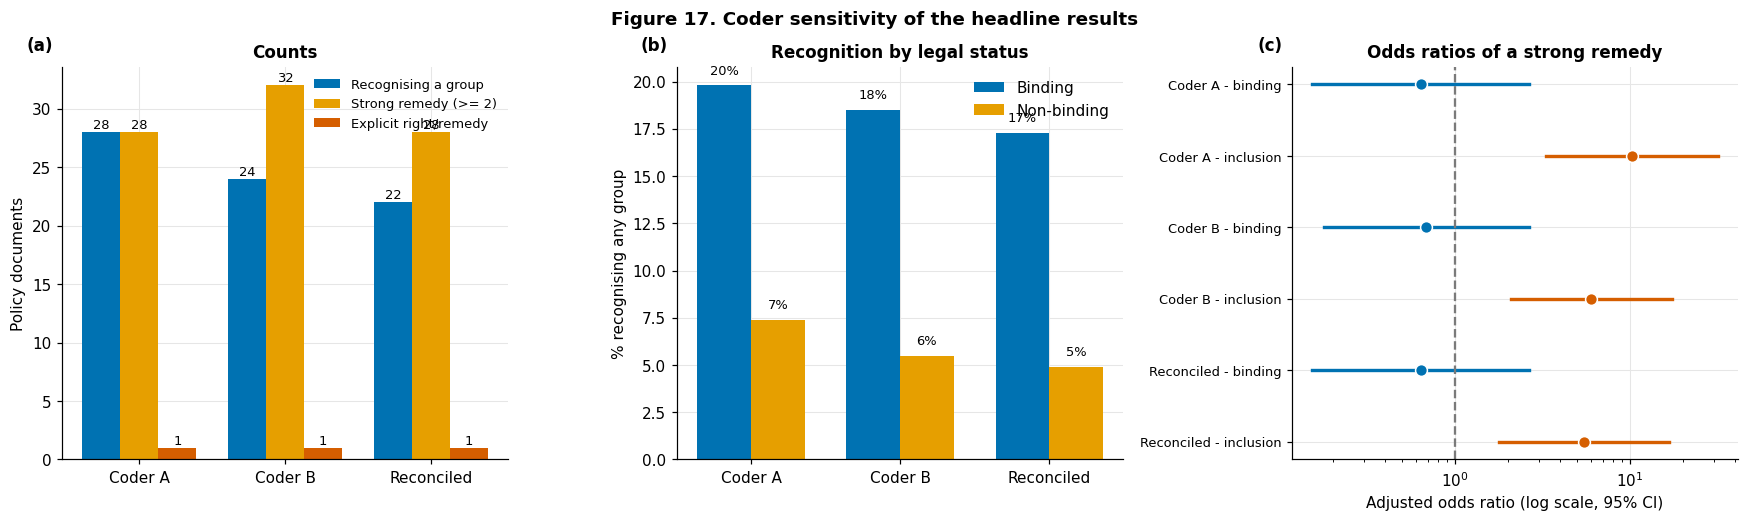

In [14]:
CODINGS = {"Coder A (strict)": "A_", "Coder B (loose)": "B_", "Reconciled (min of A, B)": ""}
rows, orrows = [], []
for lab, pre in CODINGS.items():
    inc, strong, expl = pol[f"{pre}inclusion"], pol[f"{pre}procedural_or_enforceable"], pol[f"{pre}enforceable_remedy"]
    rows.append({"coding": lab, "n_recognising_any_group": int(inc.sum()),
                 "pct_recognising_binding": round(100 * inc[pol["is_binding"]].mean(), 1),
                 "pct_recognising_nonbinding": round(100 * inc[~pol["is_binding"]].mean(), 1),
                 "n_strong_remedy": int(strong.sum()), "n_explicit_right_remedy": int(expl.sum()),
                 "mean_accountability_index": round(pol[f"{pre}accountability_index"].mean(), 2)})
    dd = d.copy(); dd["y"] = pol.loc[dd.index, f"{pre}procedural_or_enforceable"].values; dd["inclusion"] = pol.loc[dd.index, f"{pre}inclusion"].values
    for mname, f in [("binding (M1)", "y ~ binding + C(format3) + C(tier)"), ("inclusion (M2)", "y ~ binding + inclusion + C(format3) + C(tier)")]:
        m, note, used = fit_with_collapse(f, dd, "y")
        term = "binding" if mname.startswith("binding") else "inclusion"
        if m is not None and term in m.params.index:
            ci = m.conf_int().loc[term]
            orrows.append({"coding": lab, "term": mname, "odds_ratio": np.exp(m.params[term]), "OR_CI_low": np.exp(ci.iloc[0]), "OR_CI_high": np.exp(ci.iloc[1]), "p_value": m.pvalues[term], "status": note})
        else:
            orrows.append({"coding": lab, "term": mname, "odds_ratio": np.nan, "OR_CI_low": np.nan, "OR_CI_high": np.nan, "p_value": np.nan, "status": note})
sens = pd.DataFrame(rows).set_index("coding")
sens_or = pd.DataFrame(orrows)
show(sens, "Table 33. Coder sensitivity - headline counts and rates under each coding", "t33_sensitivity_counts")
show(sens_or.round(4), "Table 34. Coder sensitivity - adjusted odds ratios of a strong remedy (blank = not estimable)", "t34_sensitivity_odds_ratios", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]; x = np.arange(len(sens)); w = 0.26
for j, (col, lab, c) in enumerate([("n_recognising_any_group", "Recognising a group", PAL["blue"]), ("n_strong_remedy", "Strong remedy (>= 2)", PAL["orange"]), ("n_explicit_right_remedy", "Explicit right/remedy", PAL["red"])]):
    b = ax.bar(x + (j - 1) * w, sens[col], width=w, color=c, label=lab)
    for bi, v in zip(b, sens[col]): ax.text(bi.get_x() + bi.get_width() / 2, v + 0.3, int(v), ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels([s.split(" (")[0] for s in sens.index]); ax.set_ylabel("Policy documents"); ax.legend(fontsize=8.5); ax.set_title("Counts"); panel(ax, "a")
ax = axes[1]
ax.bar(x - 0.18, sens["pct_recognising_binding"], width=0.36, color=LAW_COL[b1], label="Binding"); ax.bar(x + 0.18, sens["pct_recognising_nonbinding"], width=0.36, color=LAW_COL[b2], label="Non-binding")
for xi, (a_, b_) in enumerate(zip(sens["pct_recognising_binding"], sens["pct_recognising_nonbinding"])):
    ax.text(xi - 0.18, a_ + 0.6, f"{a_:.0f}%", ha="center", fontsize=8.5); ax.text(xi + 0.18, b_ + 0.6, f"{b_:.0f}%", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels([s.split(" (")[0] for s in sens.index]); ax.set_ylabel("% recognising any group"); ax.legend(); ax.set_title("Recognition by legal status"); panel(ax, "b")
ax = axes[2]; ok = sens_or.dropna(subset=["odds_ratio"])
if len(ok):
    keys = list(zip(ok["coding"], ok["term"])); yy = np.arange(len(keys))[::-1]
    for yi, (_, r) in zip(yy, ok.iterrows()):
        c = PAL["blue"] if r["term"].startswith("binding") else PAL["red"]
        ax.plot([r["OR_CI_low"], r["OR_CI_high"]], [yi, yi], color=c, lw=2.2); ax.scatter(r["odds_ratio"], yi, color=c, s=60, edgecolor="white", zorder=3)
    ax.set_yticks(yy); ax.set_yticklabels([f"{k[0].split(' (')[0]} - {k[1].split(' ')[0]}" for k in keys], fontsize=8.5)
    ax.axvline(1, color=PAL["grey"], ls="--"); ax.set_xscale("log"); ax.set_xlabel("Adjusted odds ratio (log scale, 95% CI)")
else:
    ax.text(0.5, 0.5, "No model estimable\nunder the pre-set checks", ha="center", va="center", transform=ax.transAxes); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Odds ratios of a strong remedy"); panel(ax, "c")
plt.tight_layout(); savefig("fig17_sensitivity", "Figure 17. Coder sensitivity of the headline results")

## 10. Evidence at a glance
**What this cell does.** Draws one summary figure with the four research questions side by side and builds a **final summary table** that lists the headline statistic for each RQ in one place (the numbers are computed from the objects created above, nothing is typed in by hand).

* **RQ1** – share of policies recognising a stakeholder group (binding versus non-binding).
* **RQ2** – the recognition → protection → accountability funnel.
* **RQ3** – share of policies at each remedy level.
* **RQ4** – obligations by jurisdiction (concentration).

**Figure.** *Figure 18* 2 × 2 summary. **Output.** `t35_summary_of_findings.csv`, `fig18_evidence_at_a_glance.pdf`.

**How to read it.** Use this as the one-page overview of the study; every number can be traced back to the table named in the *source* column.

**Table 35. Summary of findings by research question**

,research_question,indicator,value,source_table
0,RQ1,Policies recognising at least one stakeholder group,22/244 (9.0%),t08
1,RQ1,Recognition: binding vs non-binding,14/81 (17.3%) vs 8/163 (4.9%),t09
2,RQ2,Stakeholder-linked procedural protection or explicit right,10/244 (4.1%),t12
3,RQ2,Stakeholder-linked explicit individual right/remedy,0/244,t12
4,RQ2,Document-level explicit right/remedy (not necessarily stakeholder-linked),1/244,t12b
5,RQ3,Policies with a strong remedy (procedural or explicit),28/244 (11.5%),t17
6,RQ3,Mean accountability index (0-5),0.74,t20
7,RQ4,Jurisdictions with recorded obligations / HHI,13 / 0.184,t28
8,RQ4,Largest jurisdiction share of obligations,eu 37.6%,t28
9,RQ4,Implementation records published / unverified,5 / 3 of 8,t31


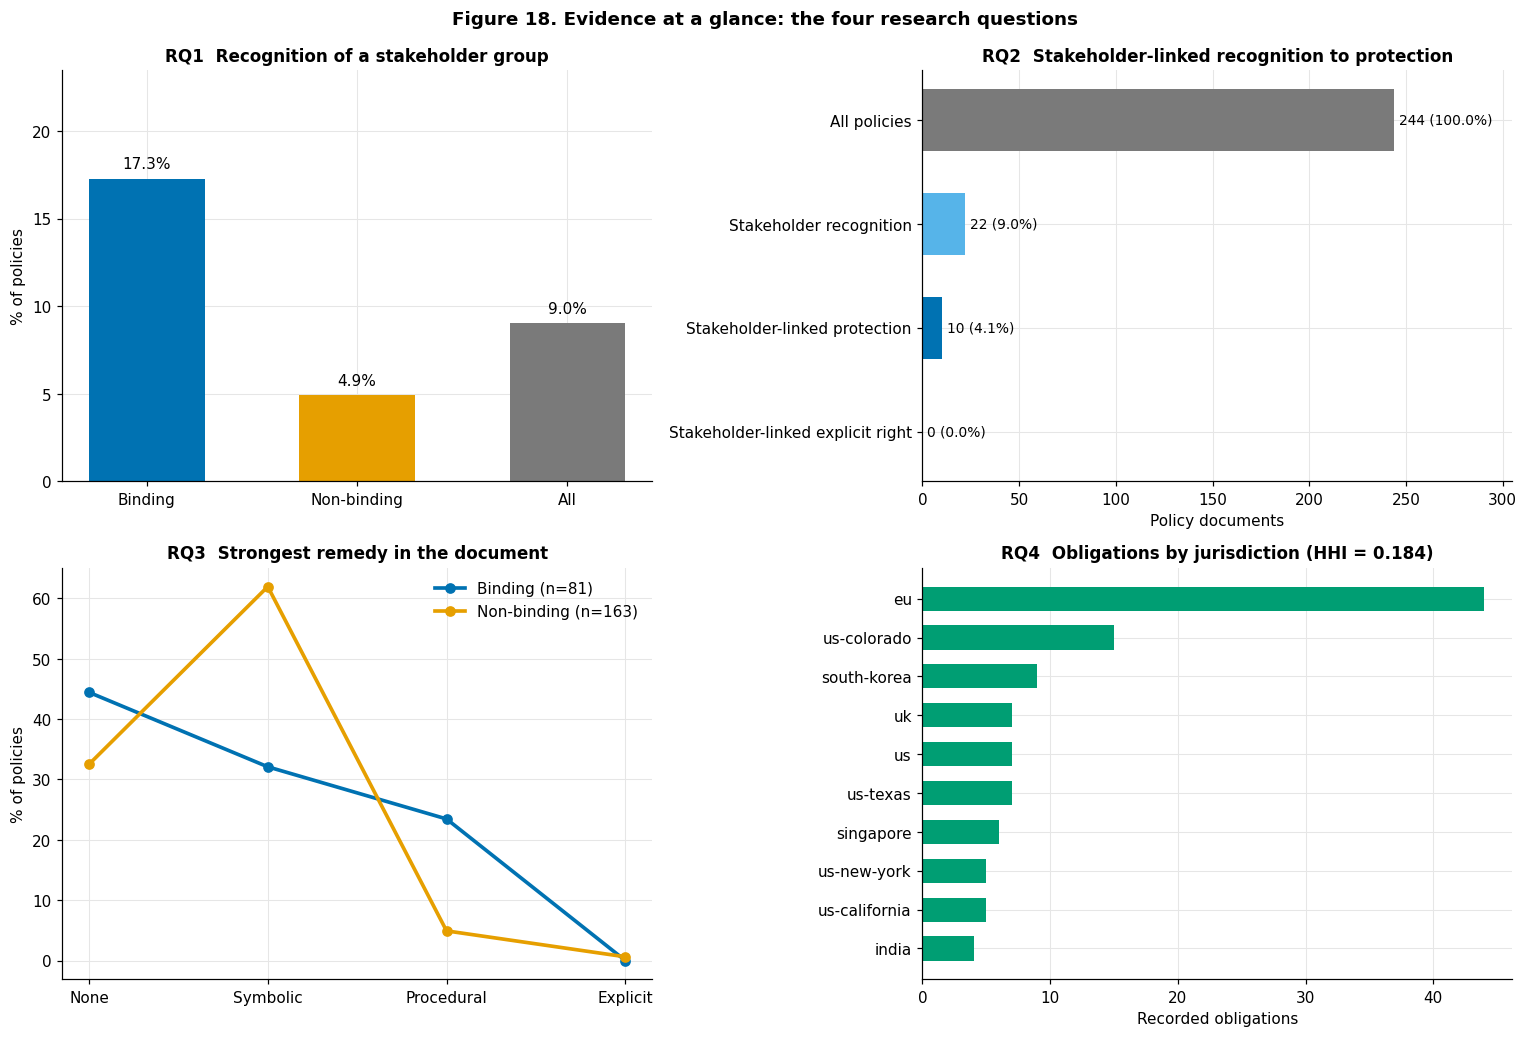

In [15]:
n_pol = len(pol)
inc_b, inc_n = pol.loc[pol["is_binding"], "inclusion"], pol.loc[~pol["is_binding"], "inclusion"]
summary = pd.DataFrame([
    ["RQ1", "Policies recognising at least one stakeholder group", f"{int(pol['inclusion'].sum())}/{n_pol} ({100 * pol['inclusion'].mean():.1f}%)", "t08"],
    ["RQ1", "Recognition: binding vs non-binding", f"{int(inc_b.sum())}/{len(inc_b)} ({100 * inc_b.mean():.1f}%) vs {int(inc_n.sum())}/{len(inc_n)} ({100 * inc_n.mean():.1f}%)", "t09"],
    ["RQ2", "Stakeholder-linked procedural protection or explicit right", f"{int((pol[[f'grp_{g}' for g in GROUPS]] >= 2).any(axis=1).sum())}/{n_pol} ({100 * (pol[[f'grp_{g}' for g in GROUPS]] >= 2).any(axis=1).mean():.1f}%)", "t12"],
    ["RQ2", "Stakeholder-linked explicit individual right/remedy", f"{int((pol[[f'grp_{g}' for g in GROUPS]] == 3).any(axis=1).sum())}/{n_pol}", "t12"],
    ["RQ2", "Document-level explicit right/remedy (not necessarily stakeholder-linked)", f"{int(pol['enforceable_remedy'].sum())}/{n_pol}", "t12b"],
    ["RQ3", "Policies with a strong remedy (procedural or explicit)", f"{int(pol['procedural_or_enforceable'].sum())}/{n_pol} ({100 * pol['procedural_or_enforceable'].mean():.1f}%)", "t17"],
    ["RQ3", "Mean accountability index (0-5)", f"{pol['accountability_index'].mean():.2f}", "t20"],
    ["RQ4", "Jurisdictions with recorded obligations / HHI", f"{len(jc)} / {hhi:.3f}", "t28"],
    ["RQ4", "Largest jurisdiction share of obligations", f"{jc.index[0]} {100 * js.iloc[0]:.1f}%", "t28"],
    ["RQ4", "Implementation records published / unverified", f"{int((imp['status'] == 'published').sum()) if 'status' in imp else 'n/a'} / {int((imp['status'] == 'unverified').sum()) if 'status' in imp else 'n/a'} of {len(imp)}", "t31"]],
    columns=["research_question", "indicator", "value", "source_table"])
show(summary, "Table 35. Summary of findings by research question", "t35_summary_of_findings", index=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.2))
ax = axes[0, 0]
vals = [100 * inc_b.mean(), 100 * inc_n.mean(), 100 * pol["inclusion"].mean()]
bars = ax.bar(["Binding", "Non-binding", "All"], vals, color=[LAW_COL[b1], LAW_COL[b2], PAL["grey"]], width=0.55)
for bar, v in zip(bars, vals): ax.text(bar.get_x() + bar.get_width() / 2, v + 0.6, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylabel("% of policies"); ax.set_title("RQ1  Recognition of a stakeholder group"); ax.set_ylim(0, max(vals) * 1.3 + 1)
ax = axes[0, 1]
gcols = [f"grp_{g}" for g in GROUPS]
fl = [n_pol, int(pol["inclusion"].sum()), int((pol[gcols] >= 2).any(axis=1).sum()), int((pol[gcols] == 3).any(axis=1).sum())]
fl_lab = ["All policies", "Stakeholder recognition", "Stakeholder-linked protection", "Stakeholder-linked explicit right"]
ax.barh(range(4)[::-1], fl, color=[PAL["grey"], PAL["sky"], PAL["blue"], PAL["red"]], height=0.6)
for yi, v in zip(range(4)[::-1], fl): ax.text(v + n_pol * 0.01, yi, f"{v} ({100 * v / n_pol:.1f}%)", va="center", fontsize=9)
ax.set_yticks(range(4)[::-1]); ax.set_yticklabels(fl_lab); ax.set_xlim(0, n_pol * 1.25); ax.set_title("RQ2  Stakeholder-linked recognition to protection"); ax.set_xlabel("Policy documents")
ax = axes[1, 0]
for lt, c in LAW_COL.items():
    sub = pol[pol["law_type"] == lt]; share = 100 * sub["remedy"].value_counts(normalize=True).reindex([0, 1, 2, 3], fill_value=0)
    ax.plot(range(4), share.values, marker="o", color=c, lw=2.4, label=f"{lt.split(' ')[0].capitalize()} (n={len(sub)})")
ax.set_xticks(range(4)); ax.set_xticklabels(["None", "Symbolic", "Procedural", "Explicit"]); ax.set_ylabel("% of policies"); ax.legend(); ax.set_title("RQ3  Strongest remedy in the document")
ax = axes[1, 1]; tp = jtab.head(10).iloc[::-1]
ax.barh(range(len(tp)), tp["n_obligations"], color=PAL["green"], height=0.62)
ax.set_yticks(range(len(tp))); ax.set_yticklabels(tp.index); ax.set_xlabel("Recorded obligations"); ax.set_title(f"RQ4  Obligations by jurisdiction (HHI = {hhi:.3f})")
plt.tight_layout(); savefig("fig18_evidence_at_a_glance", "Figure 18. Evidence at a glance: the four research questions")

## 11. Save everything as one zipped folder
**What this cell does.** Writes a **run-metadata file** (data source, licence, access date, seed, library versions, number of tables and figures) and a **manifest** that lists every saved table (CSV) and figure (PDF) with its size, then packs the whole `aipolicy_results` folder into a single archive, **`aipolicy_results.zip`**, next to it. The archive is the one file to download from Kaggle (*Output* tab) and attach to the manuscript or deposit on Zenodo.

**Research questions.** None directly; this step makes the analysis reproducible and shareable.

**How to read it.** The printed list should contain up to 35 tables (`t01`–`t35`; numbers t24 and t27 are skipped by design or appear only when the ordered-logit model is estimable, and conditional tables may be absent when a column was unavailable) and 18 figures (`fig01`–`fig18`).

In [16]:
import statsmodels, scipy, sklearn
meta = pd.DataFrame([["data_source", SOURCE_URL], ["licence", LICENCE], ["access_date", ACCESS_DATE], ["data_folder", DATA_FOLDER],
                     ["random_seed", SEED], ["bootstrap_resamples", N_BOOT], ["min_events_per_class_for_logit", MIN_EVENTS], ["min_policies_per_jurisdiction", MIN_DOCS],
                     ["n_policies", len(pol)], ["n_obligations", len(obl)], ["n_jurisdictions", len(jur)], ["n_implementation_records", len(imp)],
                     ["python", platform.python_version()], ["pandas", pd.__version__], ["numpy", np.__version__], ["scipy", scipy.__version__],
                     ["statsmodels", statsmodels.__version__], ["scikit-learn", sklearn.__version__], ["matplotlib", matplotlib.__version__],
                     ["run_timestamp_utc", datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S")]], columns=["item", "value"])
meta.to_csv(os.path.join(OUT, "run_metadata.csv"), index=False)

manifest = pd.DataFrame([{"file": f, "type": "table (CSV)"} for f in SAVED["tables"]] + [{"file": f, "type": "figure (PDF)"} for f in SAVED["figures"]])
manifest["size_kb"] = [round(os.path.getsize(os.path.join(OUT, f)) / 1024, 1) if os.path.exists(os.path.join(OUT, f)) else np.nan for f in manifest["file"]]
manifest.to_csv(os.path.join(OUT, "manifest.csv"), index=False)

ZIP_PATH = os.path.join(BASE, "aipolicy_results.zip")
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT):
        for f in sorted(files):
            full = os.path.join(root, f); z.write(full, os.path.join("aipolicy_results", os.path.relpath(full, OUT)))
with zipfile.ZipFile(ZIP_PATH) as z:
    names = z.namelist()
print(f"Saved {len(SAVED['tables'])} tables (CSV) and {len(SAVED['figures'])} figures (PDF).")
print(f"Archive: {ZIP_PATH}  ({os.path.getsize(ZIP_PATH) / 1024:.0f} KB, {len(names)} files)")
display(manifest)

Saved 38 tables (CSV) and 18 figures (PDF).
Archive: /kaggle/working/aipolicy_results.zip  (455 KB, 58 files)


,file,type,size_kb
0,t01_data_dictionary.csv,table (CSV),0.7
1,t02_data_quality.csv,table (CSV),0.4
2,t03_corpus_composition.csv,table (CSV),0.3
3,t04_format_by_law_type.csv,table (CSV),0.2
4,t05_codebook.csv,table (CSV),1.3
5,t06_inter_method_agreement.csv,table (CSV),1.5
6,t07_disagreement_audit_list.csv,table (CSV),4.8
7,human_validation_template.csv,table (CSV),14.5
8,t08_rq1_recognition_by_group.csv,table (CSV),0.4
9,t09_rq1_binding_vs_nonbinding_by_group.csv,table (CSV),0.5
